# Dự đoán tái nhập viện <30 ngày ở bệnh nhân tiểu đường
## Toàn bộ Bước 1–6: từ EDA đến so sánh ba thuật toán

Notebook dùng chung mã trong `src/` và `main.py`. Chọn kernel `.venv`, rồi **Run All**.
Bảng, mô hình và ảnh lưu trong `outputs/`. Khi mô hình hiện có khớp dữ liệu/mã/cấu hình,
notebook tái sử dụng; nếu chưa có sẽ chạy CV thật, có thể mất vài phút.

**Thời điểm dự đoán là lúc xuất viện.** Nhãn dương UCI là `<30`, âm là `NO` / `>30`.
Đây là dự án học tập, chưa phải mô hình đã kiểm định triển khai lâm sàng.

Các phần lần lượt trình bày EDA, cohort, tiền xử lý, chọn biến bằng hai phương pháp,
Logistic Regression / Random Forest / LightGBM, chọn ngưỡng và đánh giá cuối cùng trên Test.

### 1. Môi trường và đường dẫn
Cài bằng `python -m pip install -r requirements.txt` trong môi trường ảo. Không cài thư viện tự động trong notebook. Seed chung là 42.

In [1]:
from pathlib import Path
import sys
import json
import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import display, Image, Markdown

ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src' / 'preprocessing.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở notebook trong thư mục DataMining hoặc notebooks của dự án.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUTPUT_DIR = ROOT / 'outputs'
from src.preprocessing import (TARGET, ID_COLUMNS, EXCLUDED_DISCHARGES,
    load_diabetes_data, load_id_mappings, prepare_cohort, split_cohort,
    build_preprocessor, get_numeric_transform_report)
from main import run_preprocessing
print('Python:', sys.version.split()[0])
print('Project:', ROOT)


Python: 3.12.16
Project: D:\DataMining


### 2. Đọc dữ liệu và EDA mô tả
`?`, `Unknown/Invalid` và chuỗi rỗng được chuẩn hóa thành `NaN`. Chú ý: **chuỗi `None` ở xét nghiệm nghĩa là chưa đo**, cần giữ lúc đọc CSV; không để pandas tự coi là dữ liệu thiếu thông thường.

Thống kê toàn bộ dữ liệu dưới đây chỉ mô tả nguồn. Các quyết định học từ phân phối đặc trưng (lọc cột, log, impute, vocabulary, scale) dùng Train. Không chọn biến hay threshold từ Test.

In [2]:
raw = load_diabetes_data(ROOT / 'diabetic_data.csv')
mappings = load_id_mappings(ROOT / 'IDS_mapping.csv')
print(f'Dữ liệu nguồn: {raw.shape[0]:,} dòng × {raw.shape[1]} cột')
display(raw['readmitted'].value_counts().rename('count').to_frame().assign(
    percent=lambda frame: frame['count'] / len(raw) * 100))
schema = pd.DataFrame({'dtype': raw.dtypes.astype(str),
    'missing_count': raw.isna().sum(), 'missing_percent': raw.isna().mean() * 100,
    'unique_values': raw.nunique(dropna=True)}).sort_values('missing_percent', ascending=False)
display(schema)
display(pd.DataFrame({lab: raw[lab].value_counts(dropna=False)
    for lab in ['max_glu_serum', 'A1Cresult']}).fillna(0).astype(int))


Dữ liệu nguồn: 101,766 dòng × 50 cột


,count,percent
readmitted,,
NO,54864,53.911916
>30,35545,34.928169
<30,11357,11.159916


,dtype,missing_count,missing_percent,unique_values
weight,object,98569,96.858479,9
medical_specialty,object,49949,49.082208,72
payer_code,object,40256,39.557416,17
race,object,2273,2.233555,5
diag_3,object,1423,1.398306,789
diag_2,object,358,0.351787,748
diag_1,object,21,0.020636,716
gender,object,3,0.002948,2
patient_nbr,object,0,0.000000,71518
encounter_id,object,0,0.000000,101766


,max_glu_serum,A1Cresult
>200,1485,0
>300,1264,0
>7,0,3812
>8,0,8216
None,96420,84748
Norm,2597,4990


### 2.1. Cohort, ca tử vong/hospice và nhãn nhị phân
Mỗi bệnh nhân giữ một bản ghi có `encounter_id` dạng số nhỏ nhất, rồi loại disposition **11, 13, 14, 19, 20, 21**. Làm theo thứ tự này tránh thay ca đầu đã bị loại bằng một ca muộn hơn.

**Giới hạn:** CSV không có ngày nhập viện. ID nhỏ nhất là quy ước chọn bản ghi đại diện tái lập được, không chứng minh đây là lần nhập viện đầu theo thời gian. Sau chọn một bản ghi mỗi bệnh nhân, tỷ lệ dương có thể thay đổi so với khoảng 11% trong dữ liệu ban đầu.

Nhãn: `1 = readmitted == '<30'`; `0 = NO hoặc >30`. Nhãn thiếu/ngoài danh sách gây lỗi, không bị biến thành âm tính.

In [3]:
display(pd.DataFrame({'discharge_id': EXCLUDED_DISCHARGES,
    'description': [mappings['discharge_disposition_id'][str(code)] for code in EXCLUDED_DISCHARGES]}))
cohort, audit = prepare_cohort(raw)
display(pd.DataFrame([audit]).T.rename(columns={0: 'value'}))
assert cohort['patient_nbr'].is_unique
assert set(cohort[TARGET].unique()) == {0, 1}


,discharge_id,description
0,11,Expired
1,13,Hospice / home
2,14,Hospice / medical facility
3,19,"Expired at home. Medicaid only, hospice."
4,20,"Expired in a medical facility. Medicaid only, ..."
5,21,"Expired, place unknown. Medicaid only, hospice."


,value
raw_rows,101766
unique_patients_before_exclusions,71518
repeated_encounters_removed,30248
death_hospice_removed_after_deduplication,1545
cohort_rows,69973
positive_count,6277
positive_rate,0.089706
excluded_discharge_ids,"[11, 13, 14, 19, 20, 21]"
representative_encounter,minimum_numeric_encounter_id_before_discharge_...
chronology_limitation,No admission timestamp in supplied CSV; ID ord...


### 2.2. Chia Train/Test theo tỷ lệ 80/20
Chia có phân tầng, seed 42, sau khi giữ một bản ghi/bệnh nhân. Kiểm tra giao bệnh nhân bằng 0. ID và nhãn gốc được bỏ khỏi X; ID chỉ dùng riêng để kiểm toán split. Chưa áp dụng SMOTE hay chọn đặc trưng.

In [4]:
splits = split_cohort(cohort)
overlap = set(splits.train_ids['patient_nbr']) & set(splits.test_ids['patient_nbr'])
assert len(overlap) == 0
assert not set([*ID_COLUMNS, 'readmitted', TARGET]) & set(splits.X_train.columns)
display(pd.DataFrame([{'partition': name, 'rows': len(getattr(splits, f'y_{name}')),
    'positive_count': int(getattr(splits, f'y_{name}').sum()),
    'positive_rate': getattr(splits, f'y_{name}').mean()} for name in ['train', 'test']]))
print('Bệnh nhân trùng Train/Test:', len(overlap))


,partition,rows,positive_count,positive_rate
0,train,55978,5022,0.089714
1,test,13995,1255,0.089675


Bệnh nhân trùng Train/Test: 0


### 3. Kỹ thuật đặc trưng y tế và Pipeline
- **ICD-9:** 9 nhóm theo Strack et al. (2014, Table 2), thêm `Missing` khi không ghi nhận. Ví dụ 250.xx → Diabetes; 390–459/785 → Circulatory; mã E/V → Other. Không One-Hot mã chẩn đoán gốc.
- **Tuổi:** thứ tự từ `[0-10)` đến `[90-100)`; **xét nghiệm:** Norm < >200 < >300 và Norm < >7 < >8. Severity chưa đo được impute từ Train, có cờ `*_measured` và missing indicator để phân biệt với bình thường. Mã ordinal không phải thứ tự nguy cơ đã được chứng minh.
- **Thuốc:** hướng Down < Steady < Up, thêm cờ được kê cho từng thuốc. No dùng hướng không đổi và `prescribed=0`; phân biệt không kê với dùng liều ổn định. Đây là mã hướng thay đổi, không phải liều dùng. `change`/`diabetesMed` thành 0/1.
- **Tương tác:** tổng lượt ngoại trú/cấp cứu/nội trú trước đợt nhập viện; số thuốc đổi/tăng/giảm liều và được kê. Trạng thái thiếu có biến đếm riêng; không tự suy ra một lần thay đổi chưa ghi nhận.
- **Biến số:** impute median Train → log1p khi skew Train >1 → RobustScaler. Ordinal/binary đi qua nhánh riêng. Mã hành chính là nominal, được ánh xạ qua IDS_mapping.
- **Thiếu dữ liệu:** bỏ cố định weight/examide/citoglipton. Các cột còn lại quá thiếu/hằng số được xác định khi fit; race/payer_code/medical_specialty/chẩn đoán thiếu thành nhóm Missing.

`build_preprocessor()` trả pipeline **chưa fit**: ClinicalFeatureEngineer → TrainOnlyColumnFilter → ColumnTransformer. Bên trong hàm dùng chung: chỉ `fit_transform(X_train, y_train)`, còn Test chỉ gọi `transform(X_test)`.

In [5]:
# Dùng cùng entry point với CLI để lưu đầy đủ bảng, ma trận và ảnh.
# Hàm lặp lại quy tắc cohort/split seed 42; chỉ fit một pipeline trên Train.
summary = run_preprocessing(ROOT, OUTPUT_DIR)
preprocessor = joblib.load(OUTPUT_DIR / 'artifacts' / 'preprocessor.joblib')
X_train_transformed = sparse.load_npz(OUTPUT_DIR / 'processed' / 'X_train_preprocessed.npz')
X_test_transformed = sparse.load_npz(OUTPUT_DIR / 'processed' / 'X_test_preprocessed.npz')
assert X_train_transformed.shape[0] == len(splits.y_train)
assert X_test_transformed.shape[0] == len(splits.y_test)
assert X_train_transformed.shape[1] == X_test_transformed.shape[1]
assert np.isfinite(X_train_transformed.data).all()
assert np.isfinite(X_test_transformed.data).all()
display(preprocessor)
display(pd.DataFrame({'feature': preprocessor.get_feature_names_out()}).head(25))


Hoàn tất Bước 1–3. Cohort: 69,973 bệnh nhân.
partition  rows  positive_count  positive_rate
    train 55978            5022       0.089714
     test 13995            1255       0.089675
Ma trận Train: (55978, 224); Test: (13995, 224); giao bệnh nhân: 0.
Kết quả: D:\DataMining\outputs


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('clinical_features', ...), ('column_filter', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](47,)","['race','gender','age',...,'metformin-pioglitazone','change','diabetesMed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,47
,id_mappings,"{'admission_source_id': {'1': 'Physician Referral', '10': 'Transfer from critial access hospital', '11': 'Normal Delivery', '12': 'Premature Delivery', ...}, 'admission_type_id': {'1': 'Emergency', '2': 'Urgent', '3': 'Elective', '4': 'Newborn', ...}, 'discharge_disposition_id': {'1': 'Discharged to home', '10': 'Neonate discharged to ... for neonatal aftercare', '11': 'Expired', '12': 'Still patient or expec...for outpatient services', ...}}"
Name,Type,Value
feature_names_in_,"ndarray[object](47,)","['race','gender','age',...,'metformin-pioglitazone','change','diabetesMed']"
feature_names_out_,"ndarray[object](73,)","['race','gender','age',...,'diag_1_group','diag_2_group','diag_3_group']"


,feature
0,numeric__time_in_hospital
1,numeric__num_lab_procedures
2,numeric__num_procedures
3,numeric__num_medications
4,numeric__number_outpatient
5,numeric__number_emergency
6,numeric__number_inpatient
7,numeric__number_diagnoses
8,numeric__total_prior_visits
9,numeric__n_medications_changed


In [6]:
display(get_numeric_transform_report(preprocessor, splits.X_train))
display(pd.DataFrame.from_dict(summary['additional_columns_dropped_on_train'],
    orient='index', columns=['reason']).rename_axis('feature'))
clinical = preprocessor.named_steps['clinical_features'].transform(splits.X_train)
display(clinical[['age', 'diag_1_group', 'A1Cresult', 'A1Cresult_measured',
    'insulin', 'insulin_prescribed', 'total_prior_visits', 'n_medications_changed']].head())


,feature,skew_before,skew_after,log1p
0,time_in_hospital,1.173311,0.130993,True
1,num_lab_procedures,-0.215960,-0.215960,False
2,num_procedures,1.236455,0.457567,True
3,num_medications,1.434947,-0.431602,True
4,number_outpatient,9.858446,3.151941,True
5,number_emergency,16.899238,4.262220,True
6,number_inpatient,5.659423,3.143098,True
7,number_diagnoses,-0.720953,-0.720953,False
8,total_prior_visits,6.275279,1.910147,True
9,n_medications_changed,1.585275,1.287374,True


,reason
feature,
acetohexamide,constant_on_train
tolbutamide,constant_on_train
troglitazone,constant_on_train
tolazamide,constant_on_train
glipizide-metformin,constant_on_train
glimepiride-pioglitazone,constant_on_train
metformin-rosiglitazone,constant_on_train
metformin-pioglitazone,constant_on_train
n_medications_unknown,constant_on_train


,age,diag_1_group,A1Cresult,A1Cresult_measured,insulin,insulin_prescribed,total_prior_visits,n_medications_changed
19062,[40-50),Musculoskeletal,NaN,0.0,Steady,0.0,0.0,1.0
22727,[70-80),Respiratory,NaN,0.0,Steady,0.0,1.0,0.0
38122,[80-90),Circulatory,NaN,0.0,Steady,0.0,0.0,0.0
48134,[80-90),Respiratory,NaN,0.0,Down,1.0,0.0,1.0
22888,[50-60),Other,NaN,0.0,Steady,1.0,0.0,0.0


### 3.1. Biểu đồ có thể dùng trong báo cáo
Ảnh PNG được lưu với độ phân giải 170 DPI ở `outputs/figures/`. Biểu đồ phân phối biến, độ lệch và chẩn đoán chỉ dùng Train. Biểu đồ nguồn và tỷ lệ thiếu dùng toàn bộ dữ liệu để mô tả, không dùng để lựa chọn mô hình.

Việc log1p làm giảm skewness không bảo đảm cải thiện chất lượng dự đoán; cần kiểm chứng trong CV ở giai đoạn sau. Các nhóm chẩn đoán phổ biến không tự động là đặc trưng quan trọng nhất.

**eda_class_distribution**

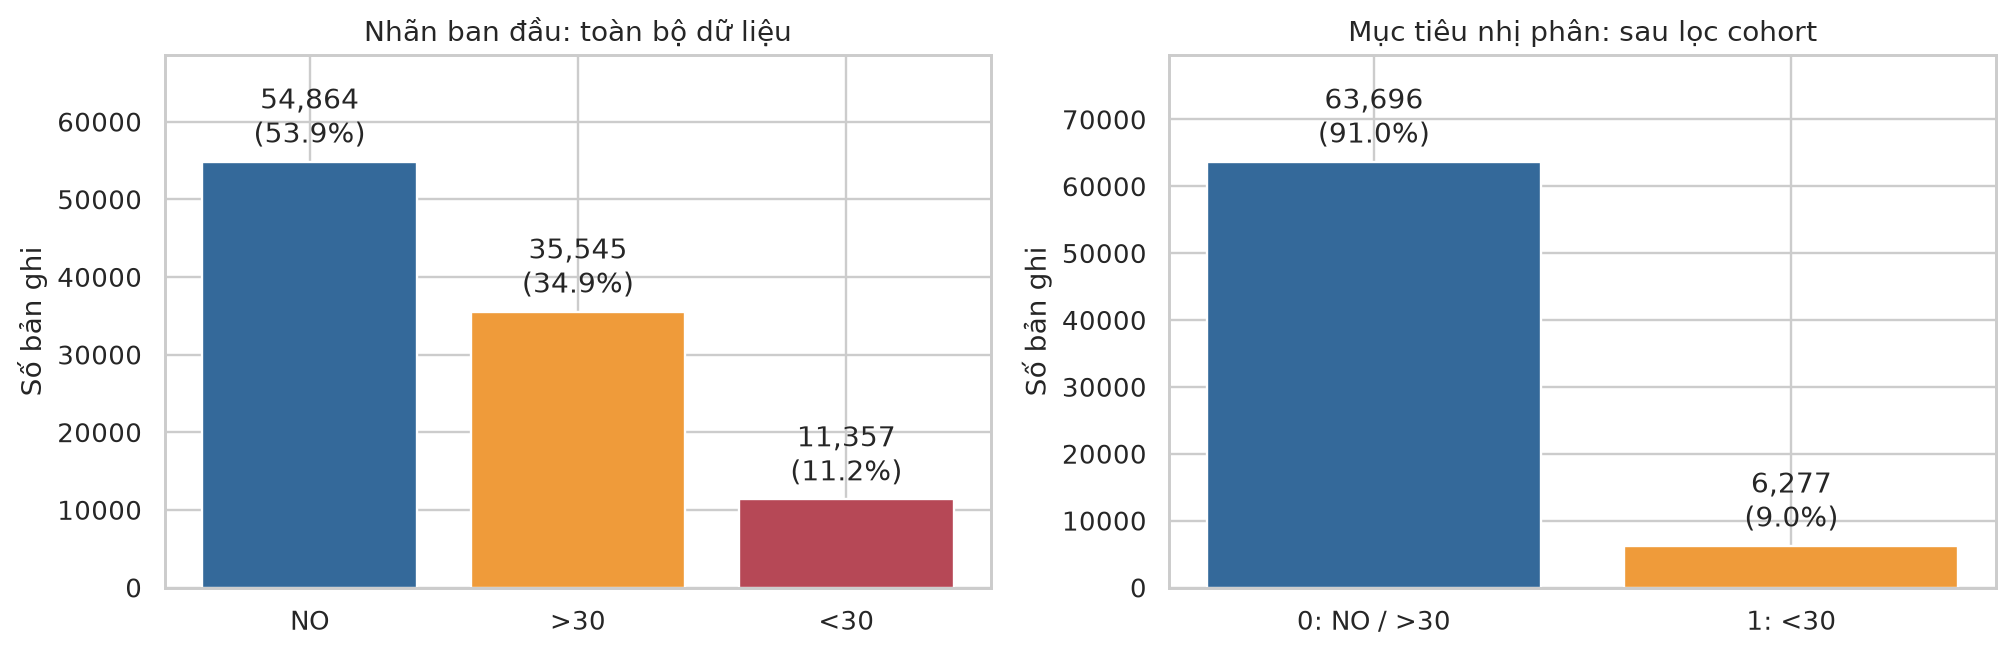

**eda_missing_values**

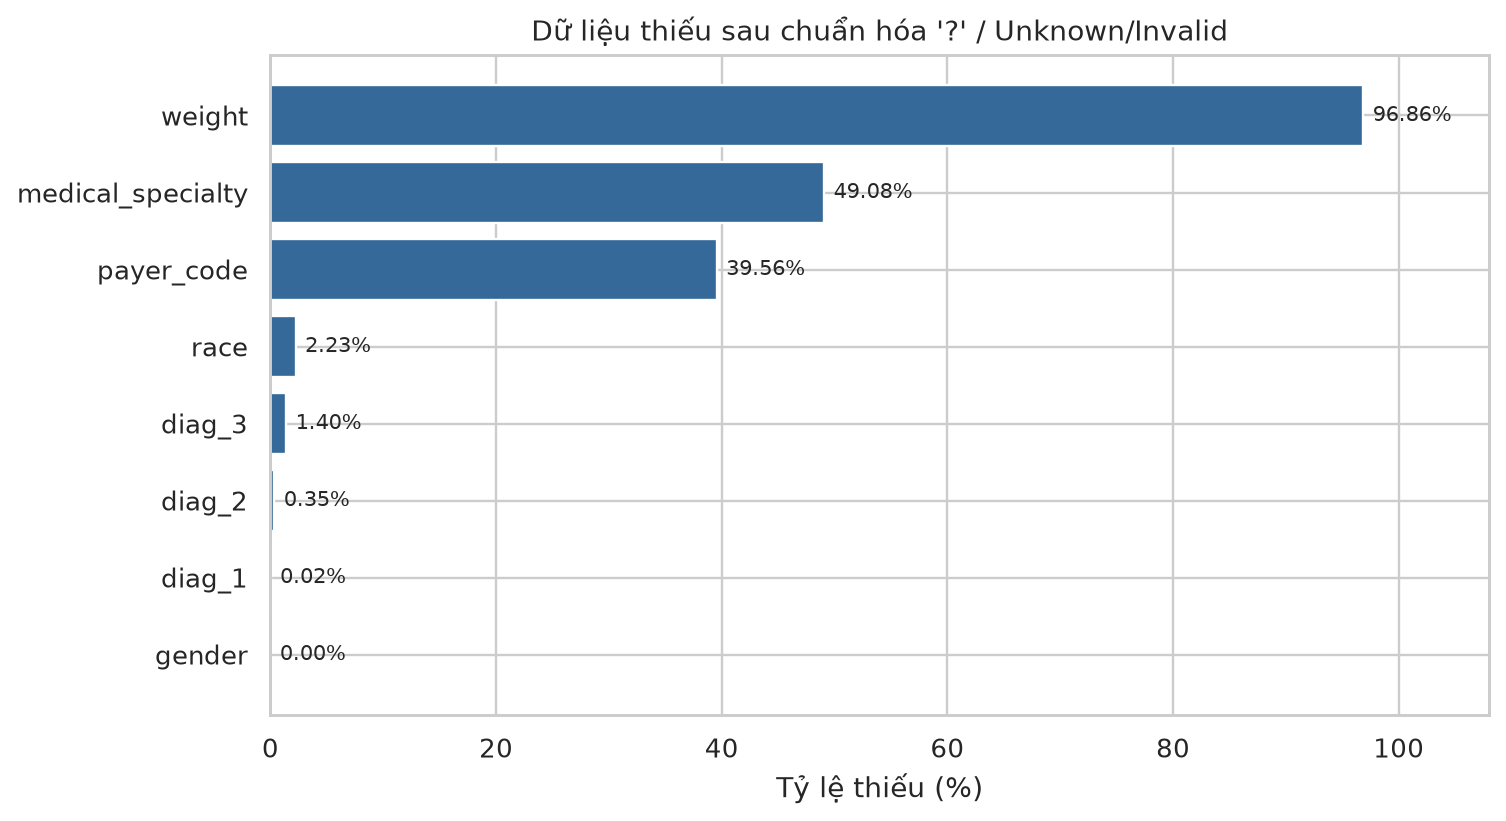

**eda_train_numeric_distributions**

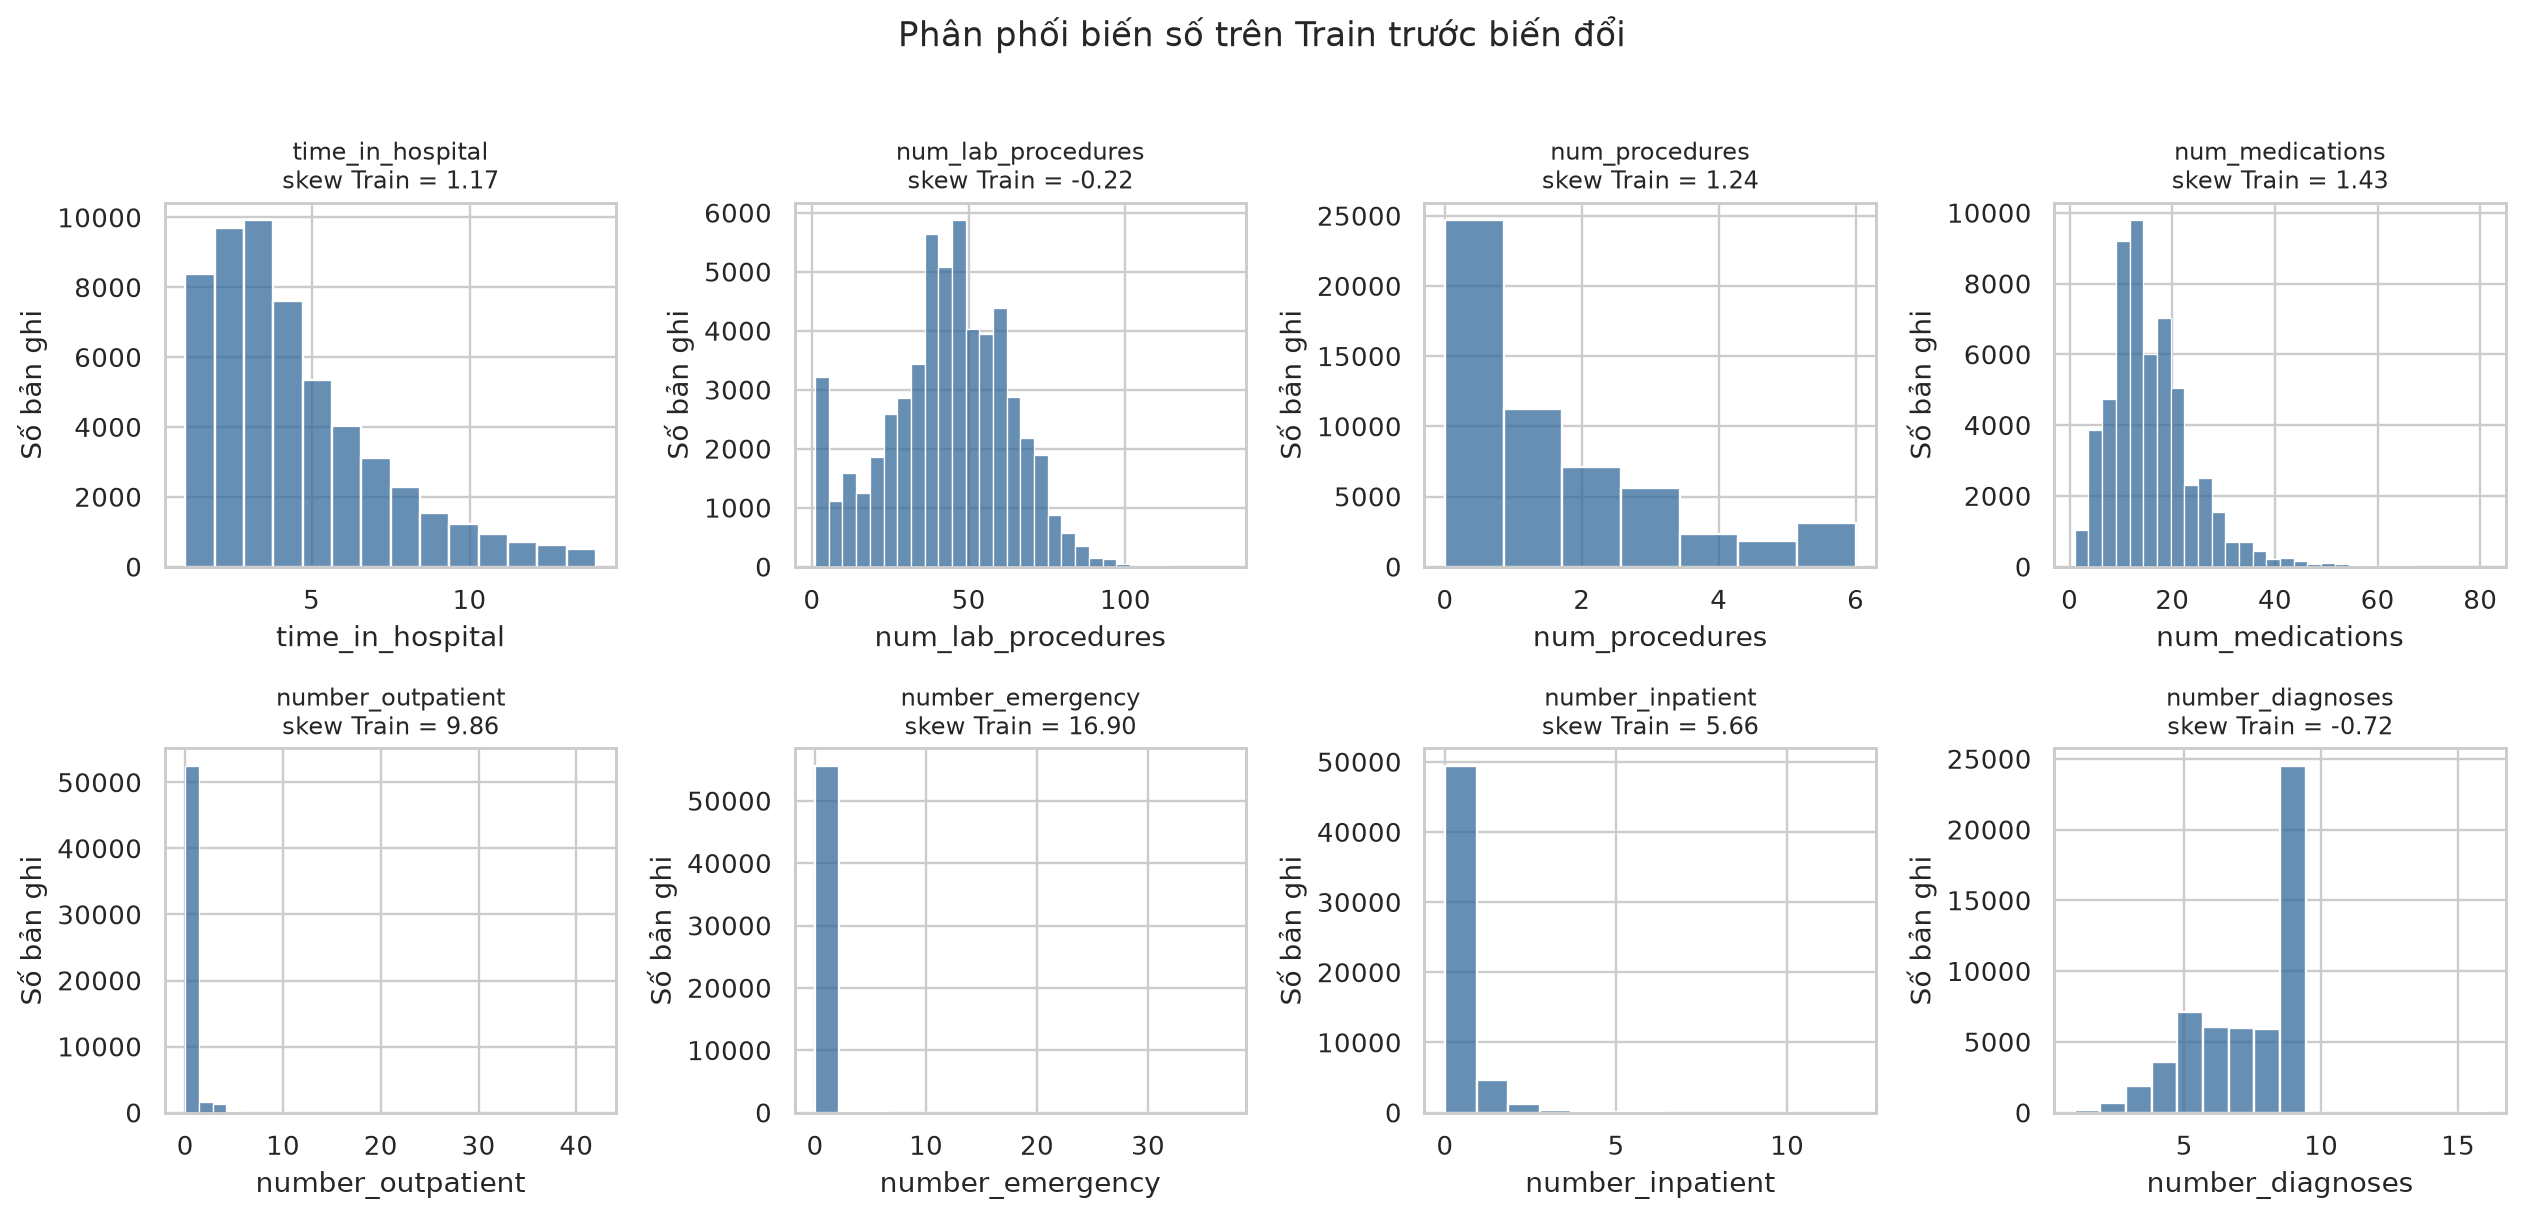

**eda_skewness_before_after**

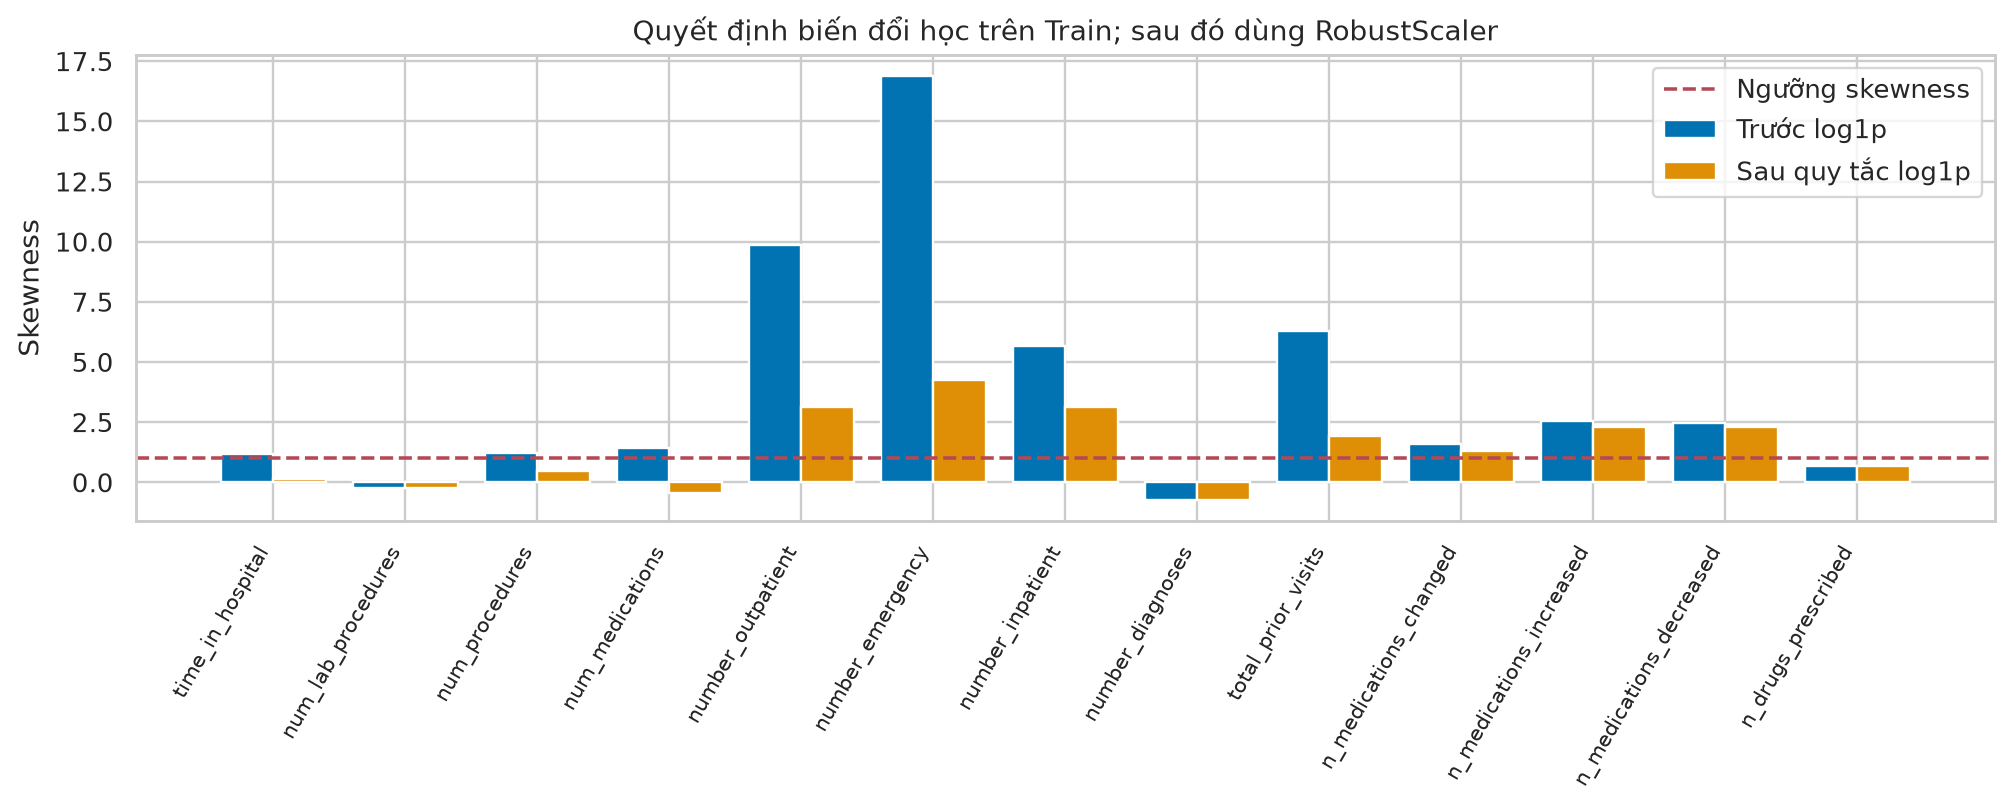

**eda_train_diagnosis_groups**

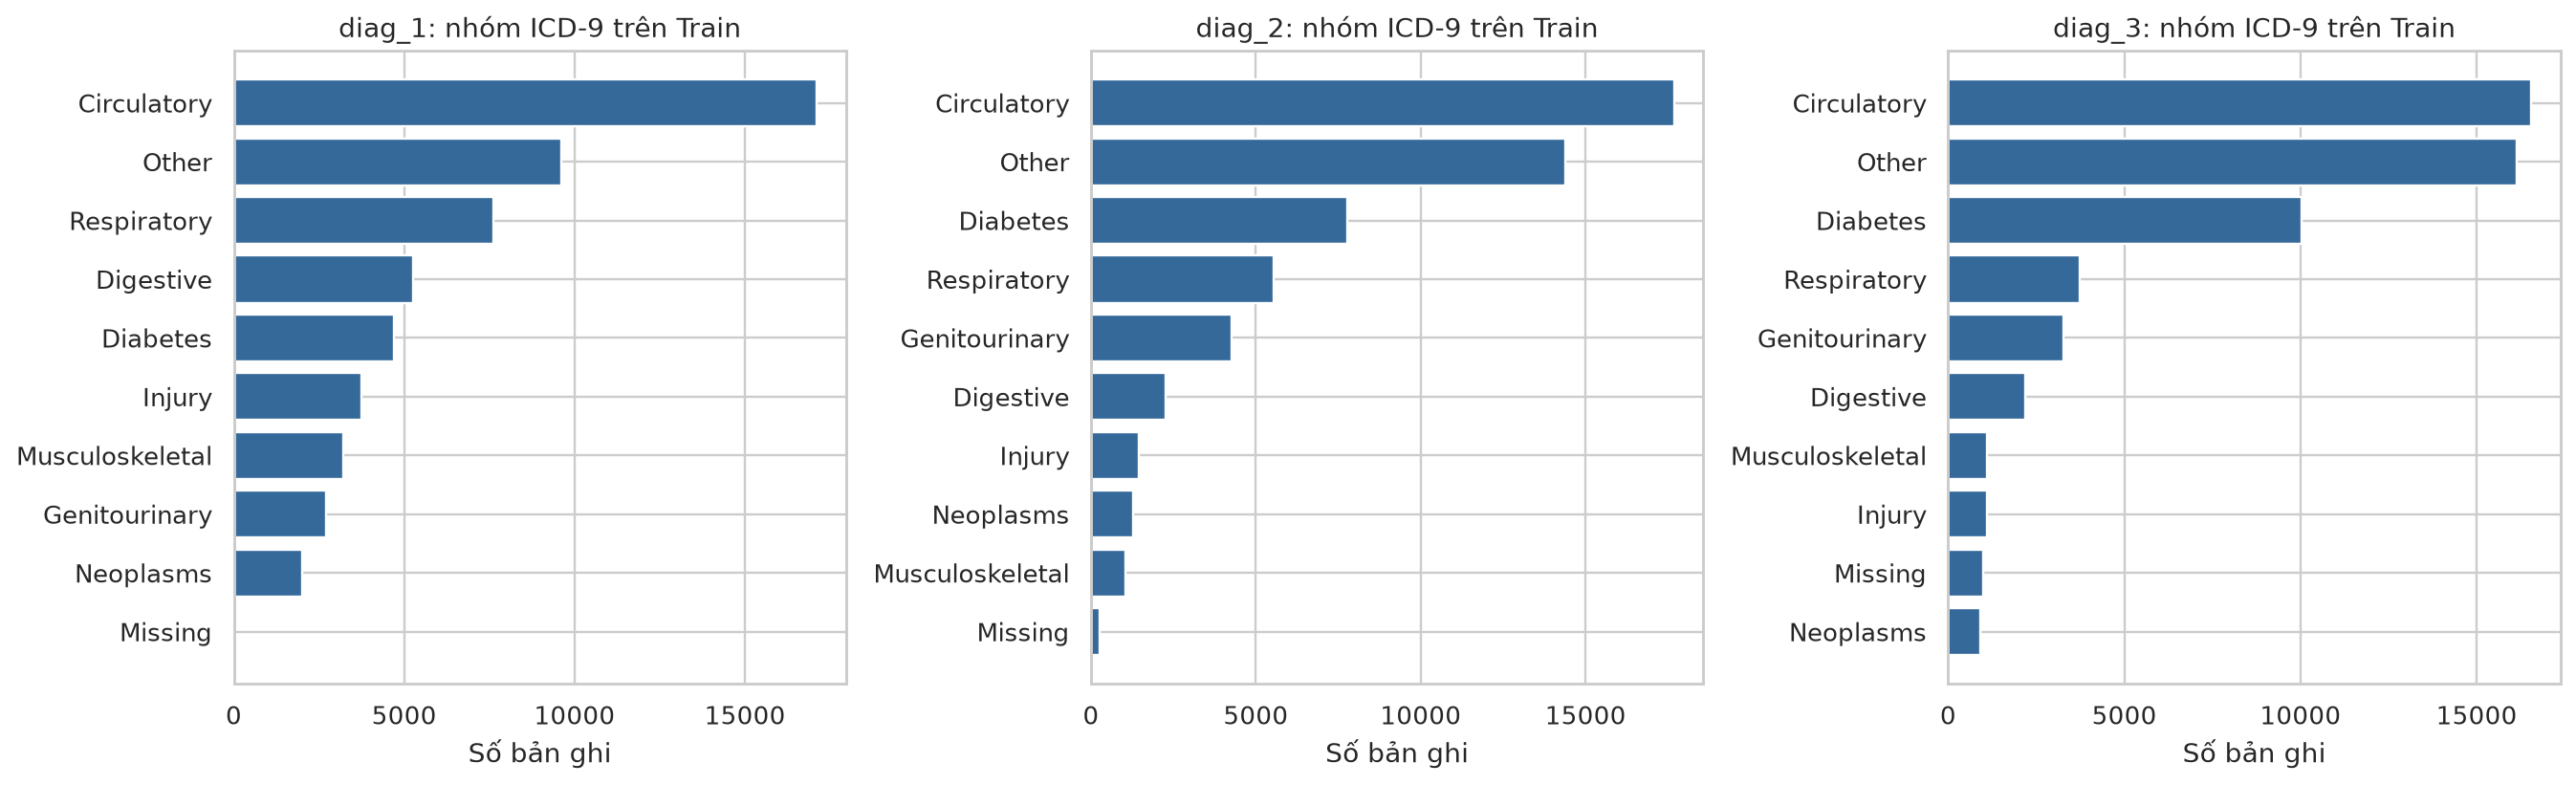

In [7]:
for name, path in summary['figures'].items():
    display(Markdown(f'**{name}**'))
    display(Image(filename=path, width=1000))


### 3.2. Kiểm tra tiền xử lý
Xác nhận không giao bệnh nhân, ma trận hữu hạn và Test không thay đổi thống kê đã fit.
Chạy thêm `python -m unittest discover -s tests -v` để kiểm tra toàn dự án.

CV tiếp theo dùng X Train raw và pipeline chưa fit trong mỗi fold, không dùng NPZ đã fit trên toàn Train.
Validation chọn threshold nằm riêng trong Train. Đọc lại raw CSV với keep_default_na=False để giữ None.

In [8]:
numeric = preprocessor.named_steps['columns'].named_transformers_['numeric']
medians_before = numeric.named_steps['imputer'].statistics_.copy()
names_before = preprocessor.get_feature_names_out().copy()
_ = preprocessor.transform(splits.X_test.iloc[:50])
np.testing.assert_array_equal(medians_before, numeric.named_steps['imputer'].statistics_)
np.testing.assert_array_equal(names_before, preprocessor.get_feature_names_out())
assert summary['patient_overlap'] == 0
assert summary['all_transformed_values_finite']
print('Đạt: không trùng bệnh nhân; ma trận hợp lệ; Test chỉ transform, không fit lại.')
print('Đã kiểm tra Bước 1–3; tiếp tục chọn biến và huấn luyện bên dưới.')


Đạt: không trùng bệnh nhân; ma trận hợp lệ; Test chỉ transform, không fit lại.
Đã kiểm tra Bước 1–3; tiếp tục chọn biến và huấn luyện bên dưới.


### 4–5. Chọn đặc trưng và tinh chỉnh ba thuật toán

Giữ outer Train/Test **80/20**. Trong Train tách development 80% / threshold validation 20%.
Development dùng RandomizedSearchCV (6 cấu hình × 3 fold mỗi thuật toán), chọn theo **Average Precision**.
Validation riêng dùng chọn ngưỡng và thuật toán; Test không tham gia.

Mỗi fold fit pipeline riêng: preprocessing → selector → classifier. Selector xếp hạng bằng
**ANOVA F-test** và **LightGBM gain**, lấy trung bình thứ hạng để chọn top-k.
`k ∈ {40,80,120,all}` được chọn trong CV cùng hyperparameter classifier; all là đối chứng.

LR/RF dùng class_weight balanced; LightGBM dùng is_unbalance tự tính mất cân bằng trong mỗi lần fit.
Không dùng SMOTE trong thí nghiệm này. Khóa tham số/ngưỡng từ development/validation,
rồi refit trên toàn outer Train và mới đánh giá Test.

Để RETRAIN=False khi muốn dùng kết quả còn phù hợp; True buộc chạy lại CV.

In [9]:
from main import run_modeling
from src.models import ExperimentConfig
RETRAIN = False
config = ExperimentConfig(n_iter=6, cv_folds=3, search_jobs=2, model_jobs=2,
                          min_precision=0.20, shap_samples=300)
experiment = run_modeling(ROOT, OUTPUT_DIR, config=config, retrain=RETRAIN)
training = json.loads((OUTPUT_DIR / 'tables' / 'training_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model': row['label'], 'CV AP': row['cv_best_average_precision'],
    'CV ROC-AUC': row['cv_best_roc_auc'], 'selected_features': row['selected_features'],
    'best_params': json.dumps(row['best_params'], ensure_ascii=False)} for row in training['models']]))
print('Development:', training['development_rows'], '| threshold validation:', training['threshold_validation_rows'])


Đã có kết quả đủ ba mô hình khớp dữ liệu/mã/cấu hình; tái sử dụng. Dùng --retrain để huấn luyện lại.


,model,CV AP,CV ROC-AUC,selected_features,best_params
0,Logistic Regression,0.160077,0.645153,80,"{""feature_selection__k"": 80, ""classifier__C"": ..."
1,Random Forest,0.165059,0.643497,80,"{""feature_selection__k"": 80, ""classifier__n_es..."
2,LightGBM,0.168334,0.646571,120,"{""feature_selection__k"": 120, ""classifier__sub..."


Development: 44782 | threshold validation: 11196


### 4.1. Hai bảng xếp hạng và tập biến được giữ

Bảng dưới thuộc thuật toán đã chọn trên validation, fit lại trên full Train.
CV đã học lại selector ở từng fold; bảng full Train phục vụ mô hình cuối và diễn giải.
P-value ANOVA chưa hiệu chỉnh đa kiểm định, không dùng tuyên bố ý nghĩa lâm sàng/nhân quả.
Tên cột đầy đủ có trong CSV; trên hình tên dài có thể rút ngắn.

,feature,anova_f,anova_pvalue_unadjusted,anova_rank,lightgbm_gain,lightgbm_rank,combined_rank,selected
0,nominal__discharge_disposition_id_Discharged t...,511.888781,7.914335e-113,2.0,22933.364683,1.0,1.5,True
1,numeric__number_inpatient,522.738782,3.626151e-115,1.0,14727.476853,2.0,1.5,True
2,nominal__discharge_disposition_id_Discharged/t...,389.991631,1.640021e-86,3.0,5571.653452,3.0,3.0,True
3,numeric__time_in_hospital,212.030997,6.061361e-48,5.0,4994.750259,4.0,4.5,True
4,numeric__total_prior_visits,269.431581,2.090212e-60,4.0,4361.368595,6.0,5.0,True
5,ordinal__age,123.385036,1.230550e-28,8.0,3653.869429,8.0,8.0,True
6,numeric__num_lab_procedures,51.111584,8.832525e-13,12.0,4767.066835,5.0,8.5,True
7,numeric__num_medications,104.503626,1.648919e-24,10.0,4292.115391,7.0,8.5,True
8,numeric__number_diagnoses,112.730672,2.618457e-26,9.0,3119.966105,9.0,9.0,True
9,nominal__discharge_disposition_id_Discharged/t...,132.869129,1.046058e-30,7.0,1779.791092,14.0,10.5,True


Giữ 120 / 224 đặc trưng cho lightgbm


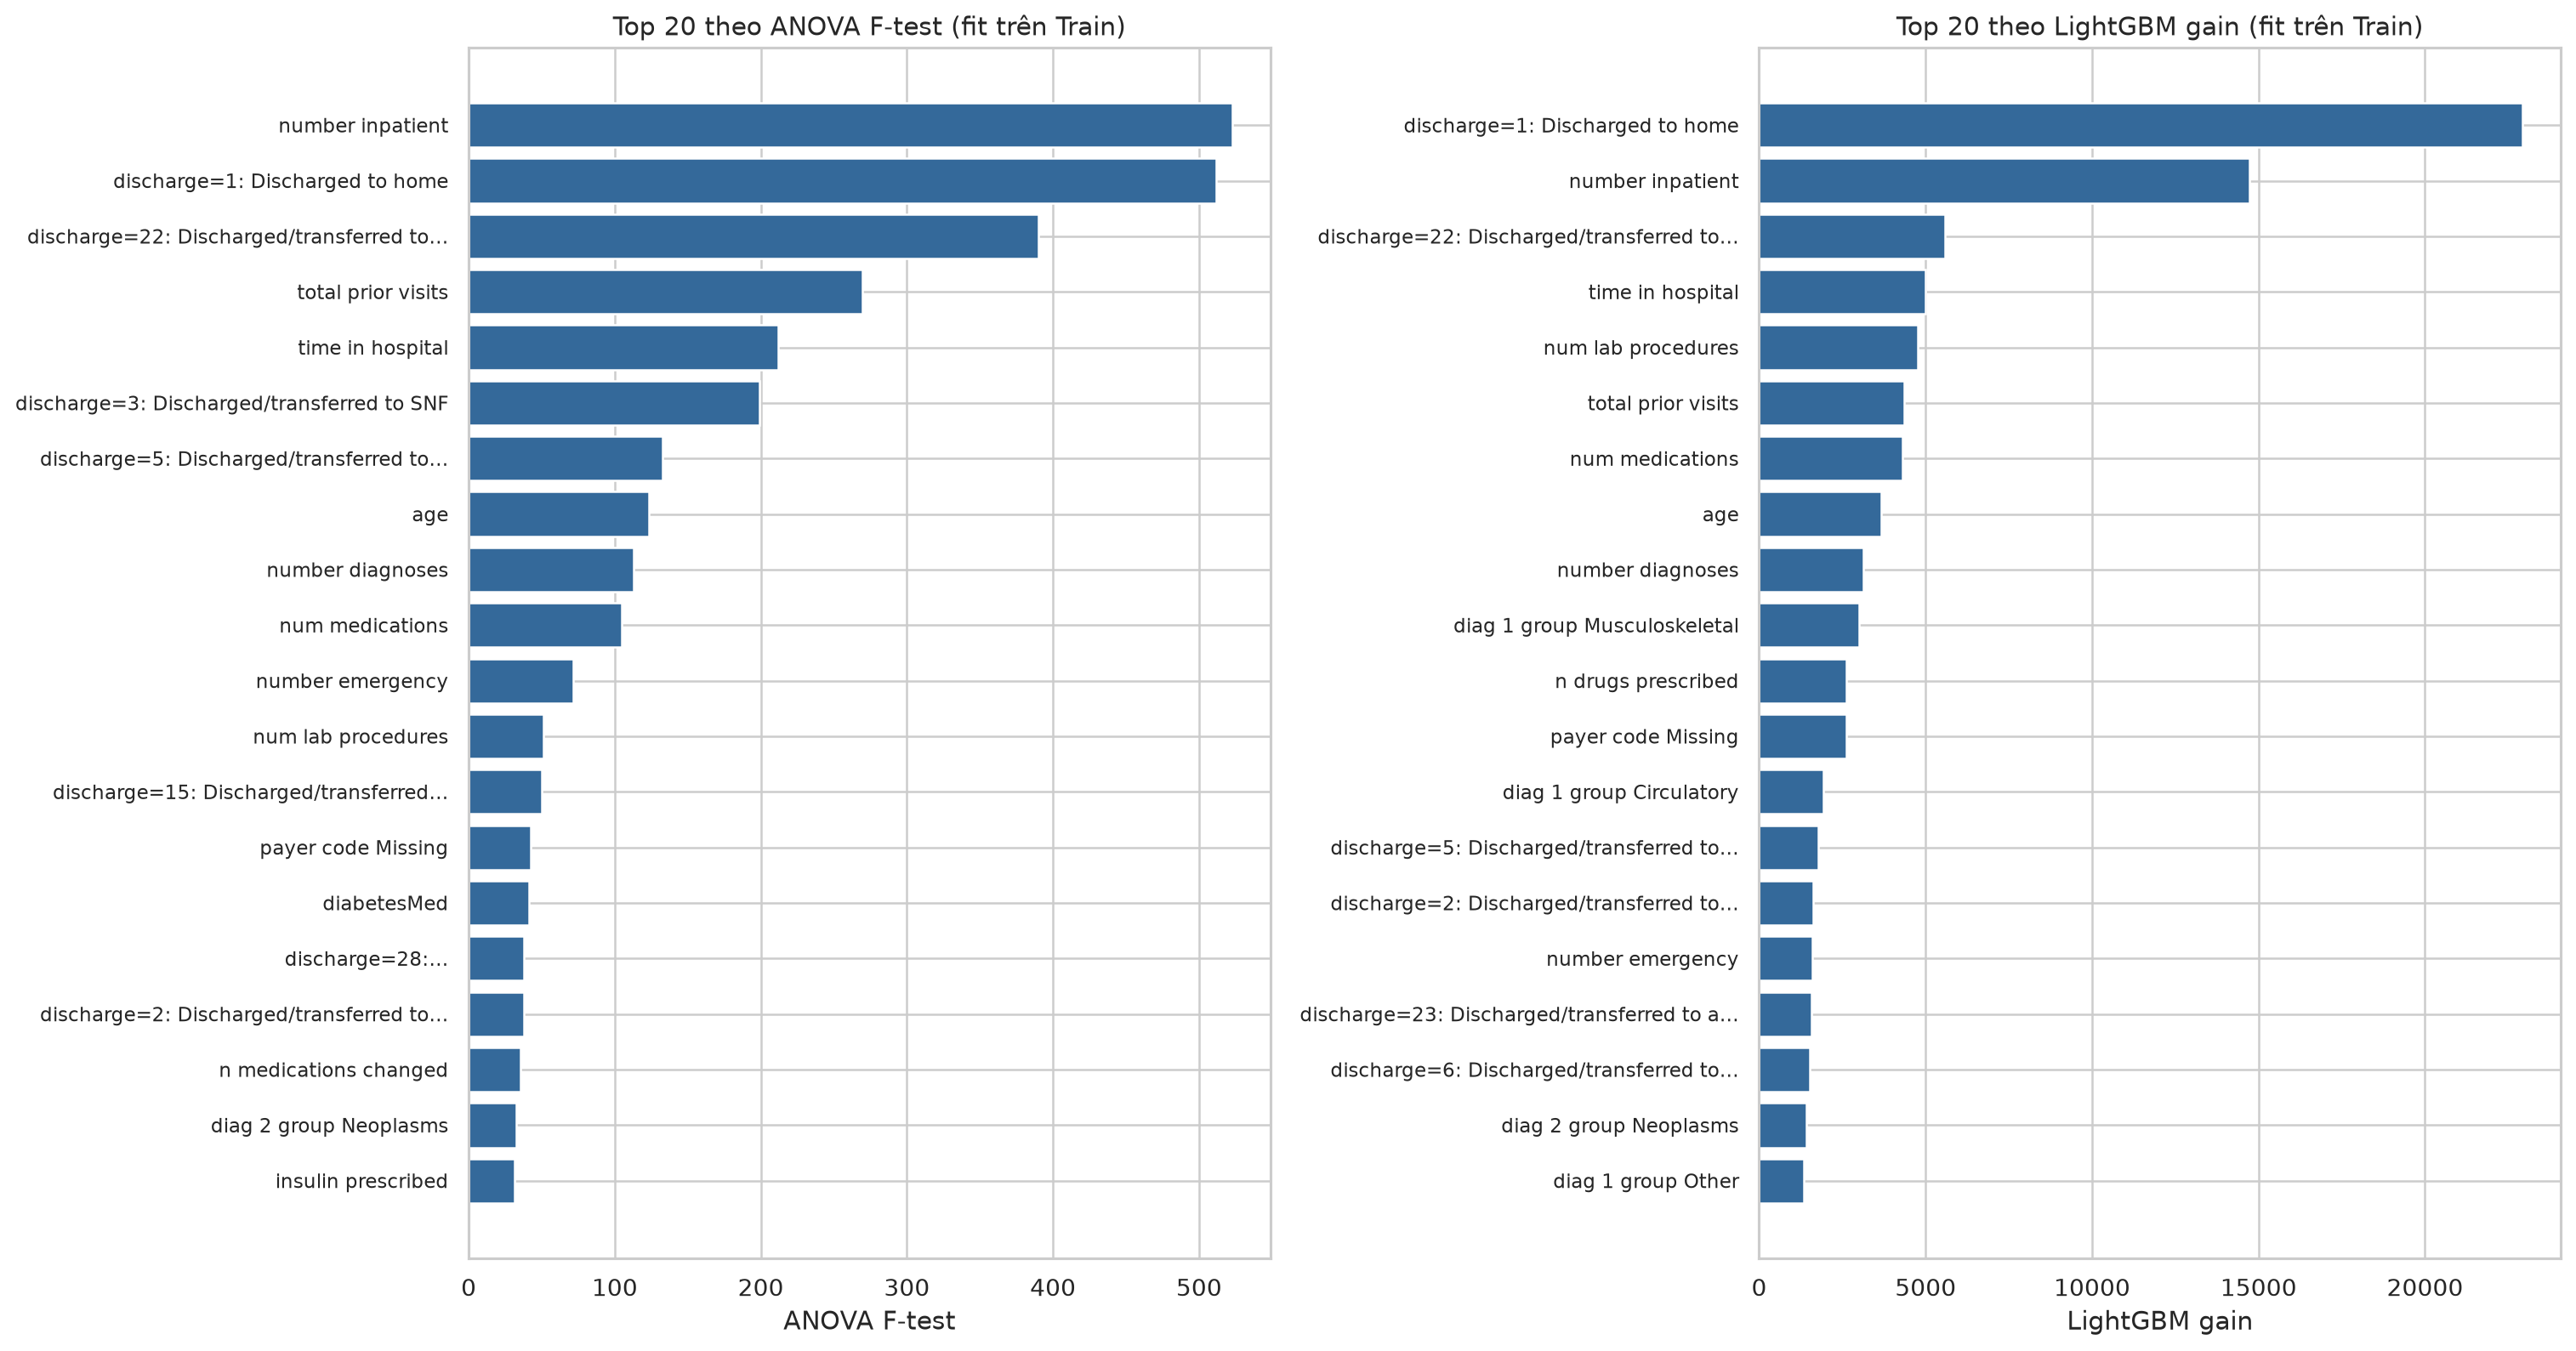

In [10]:
chosen_model = training['chosen_model']
rankings = pd.read_csv(OUTPUT_DIR / 'tables' / f'feature_selection_{chosen_model}.csv')
display(rankings.head(20))
print('Giữ', int(rankings['selected'].sum()), '/', len(rankings), 'đặc trưng cho', chosen_model)
display(Image(filename=experiment['figures']['feature_selection_methods'], width=1200))


### 6. Tối ưu ngưỡng theo Recall/F2 với ràng buộc Precision

Quét threshold **0,10–0,60**, bước **0,01**, trên validation riêng. Chọn F2 cao nhất
ở các threshold có Precision ≥20%; F2 ưu tiên Recall hơn Precision.
Nếu không threshold nào đạt, báo precision_constraint_met=False và dùng best F2 không ràng buộc.
Sàn 20% là cấu hình minh họa cho báo cáo, có thể đổi; chưa phải yêu cầu lâm sàng đã thẩm định.

Chọn thuật toán theo validation: đạt sàn → F2 → Recall → AP. Không chọn từ Test.
Sàn validation không bảo đảm Test đạt sàn. Predict_proba có trọng số lớp chưa phải xác suất nguy cơ đã hiệu chỉnh.

,model,operating_point,threshold,Recall,Precision,F1,F2,ROC_AUC,PR_AUC,Average_Precision,precision_constraint_met
0,logistic_regression,default,0.50,0.569721,0.144773,0.230878,0.358981,0.659414,0.173095,0.173798,NaN
1,logistic_regression,tuned,0.46,0.675299,0.129761,0.217691,0.366843,0.659414,0.173095,0.173798,False
2,random_forest,default,0.50,0.422311,0.165754,0.238069,0.322483,0.664007,0.184129,0.184686,NaN
3,random_forest,tuned,0.58,0.229084,0.207021,0.217494,0.224303,0.664007,0.184129,0.184686,True
4,lightgbm,default,0.50,0.561753,0.149761,0.236478,0.362375,0.674739,0.185334,0.186063,NaN
5,lightgbm,tuned,0.60,0.261952,0.201070,0.227509,0.246995,0.674739,0.185334,0.186063,True


Thuật toán chọn trước Test: lightgbm


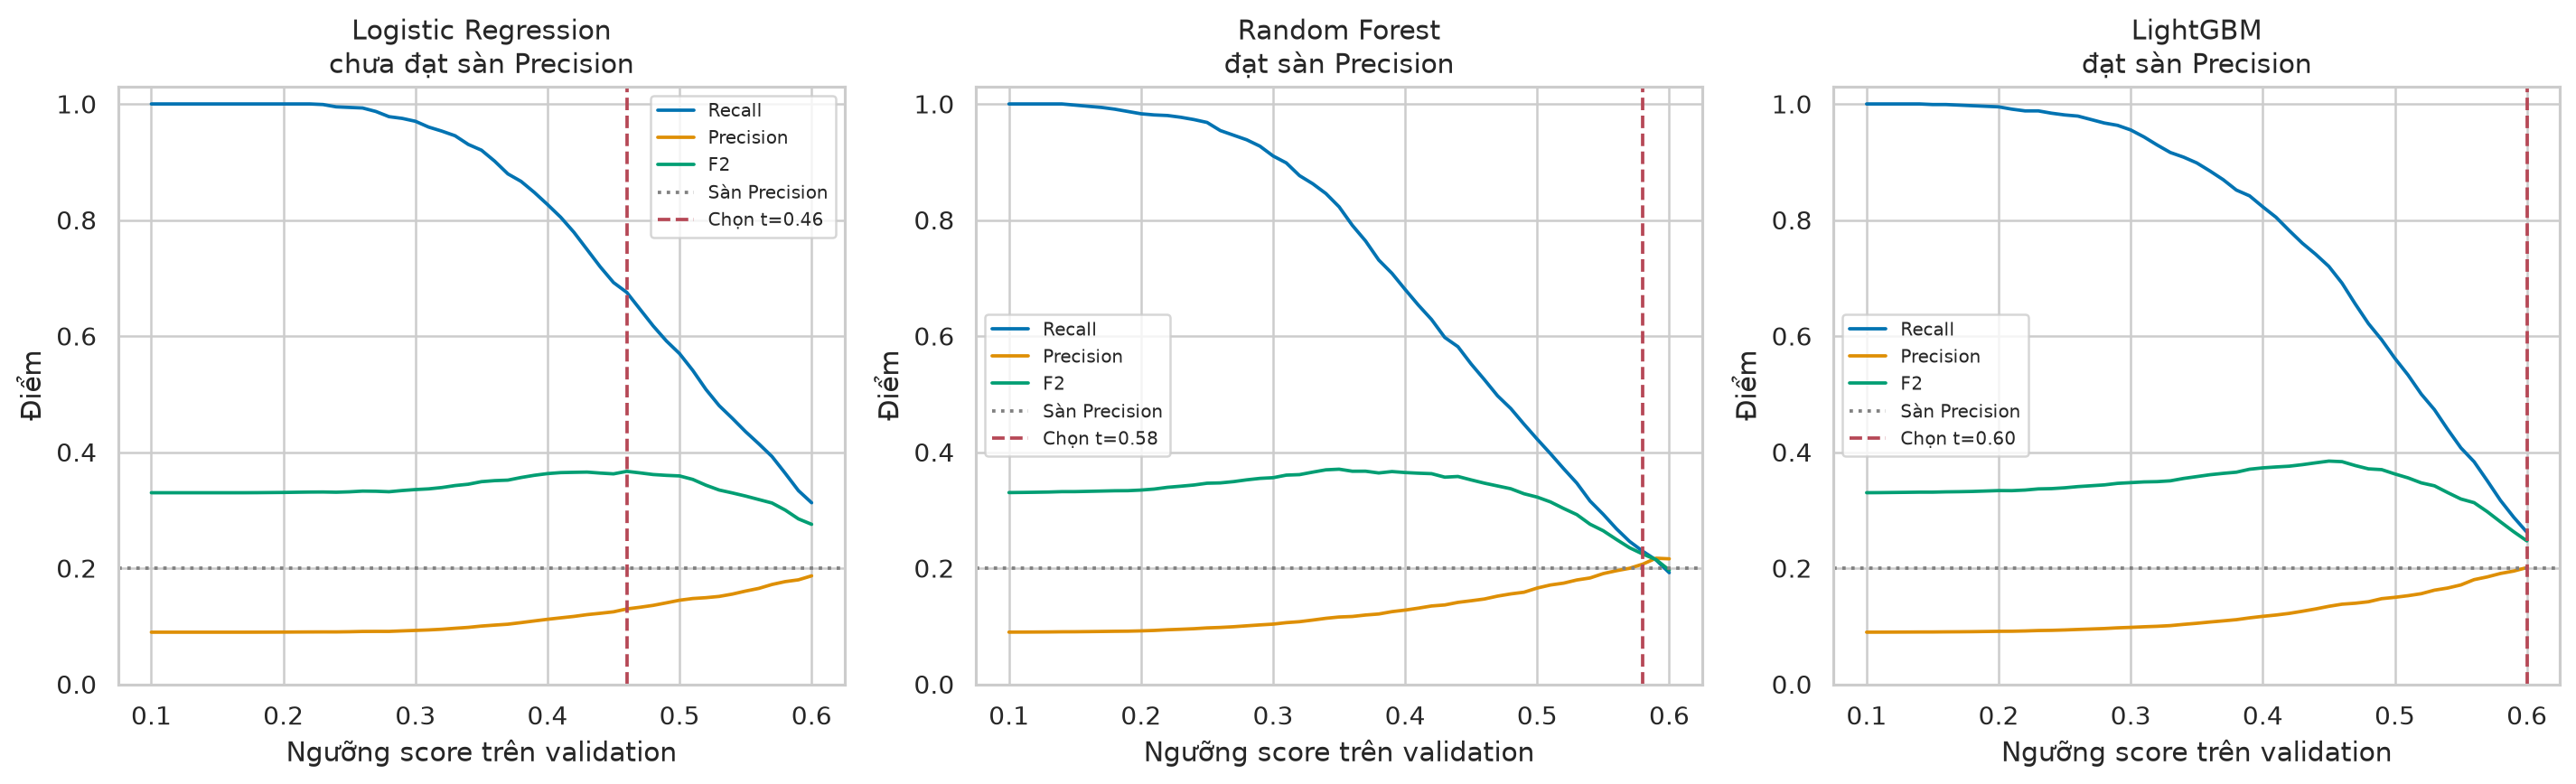

In [11]:
validation_results = pd.read_csv(OUTPUT_DIR / 'tables' / 'validation_metrics.csv')
display(validation_results[['model', 'operating_point', 'threshold', 'Recall', 'Precision', 'F1', 'F2',
                            'ROC_AUC', 'PR_AUC', 'Average_Precision', 'precision_constraint_met']])
print('Thuật toán chọn trước Test:', chosen_model)
display(Image(filename=experiment['figures']['threshold_tuning_validation'], width=1200))


### 6.1. So sánh ba thuật toán trên Test

Bảng có threshold 0,50 và threshold đã khóa; Recall/Sensitivity, Precision, F1, F2, ROC-AUC, PR-AUC, AP.
**PR-AUC dùng tích phân hình thang**, **AP dùng average_precision_score không nội suy**, báo riêng.
AUC/AP không đổi khi chỉ đổi threshold. Không đổi lựa chọn sau khi đọc bảng Test.

Baseline PR bằng tỷ lệ dương Test; điểm tròn là threshold chọn từ validation.
Ma trận nhầm lẫn cho thấy cả bỏ sót FN và báo động sai FP.

In [12]:
comparison = pd.read_csv(OUTPUT_DIR / 'tables' / 'model_comparison.csv')
display(comparison[['label', 'operating_point', 'threshold', 'selected_features', 'Recall', 'Precision',
                    'F1', 'F2', 'ROC_AUC', 'PR_AUC', 'Average_Precision', 'TN', 'FP', 'FN', 'TP']])
assert len(comparison) == 6
for model_name, group in comparison.groupby('model'):
    for metric in ['ROC_AUC', 'PR_AUC', 'Average_Precision']:
        assert group[metric].nunique() == 1


,label,operating_point,threshold,selected_features,Recall,Precision,F1,F2,ROC_AUC,PR_AUC,Average_Precision,TN,FP,FN,TP
0,Logistic Regression,default,0.50,80,0.541036,0.137477,0.219244,0.340898,0.649494,0.166504,0.167193,8480,4260,576,679
1,Logistic Regression,tuned,0.46,80,0.646215,0.125854,0.210677,0.353716,0.649494,0.166504,0.167193,7107,5633,444,811
2,Random Forest,default,0.50,80,0.409562,0.157138,0.227132,0.309975,0.646728,0.184040,0.184384,9983,2757,741,514
3,Random Forest,tuned,0.58,80,0.243825,0.209302,0.225248,0.236038,0.646728,0.184040,0.184384,11584,1156,949,306
4,LightGBM,default,0.50,120,0.534661,0.140171,0.222112,0.342103,0.655512,0.186956,0.187487,8624,4116,584,671
5,LightGBM,tuned,0.60,120,0.294821,0.208333,0.244144,0.272219,0.655512,0.186956,0.187487,11334,1406,885,370


**model_comparison**

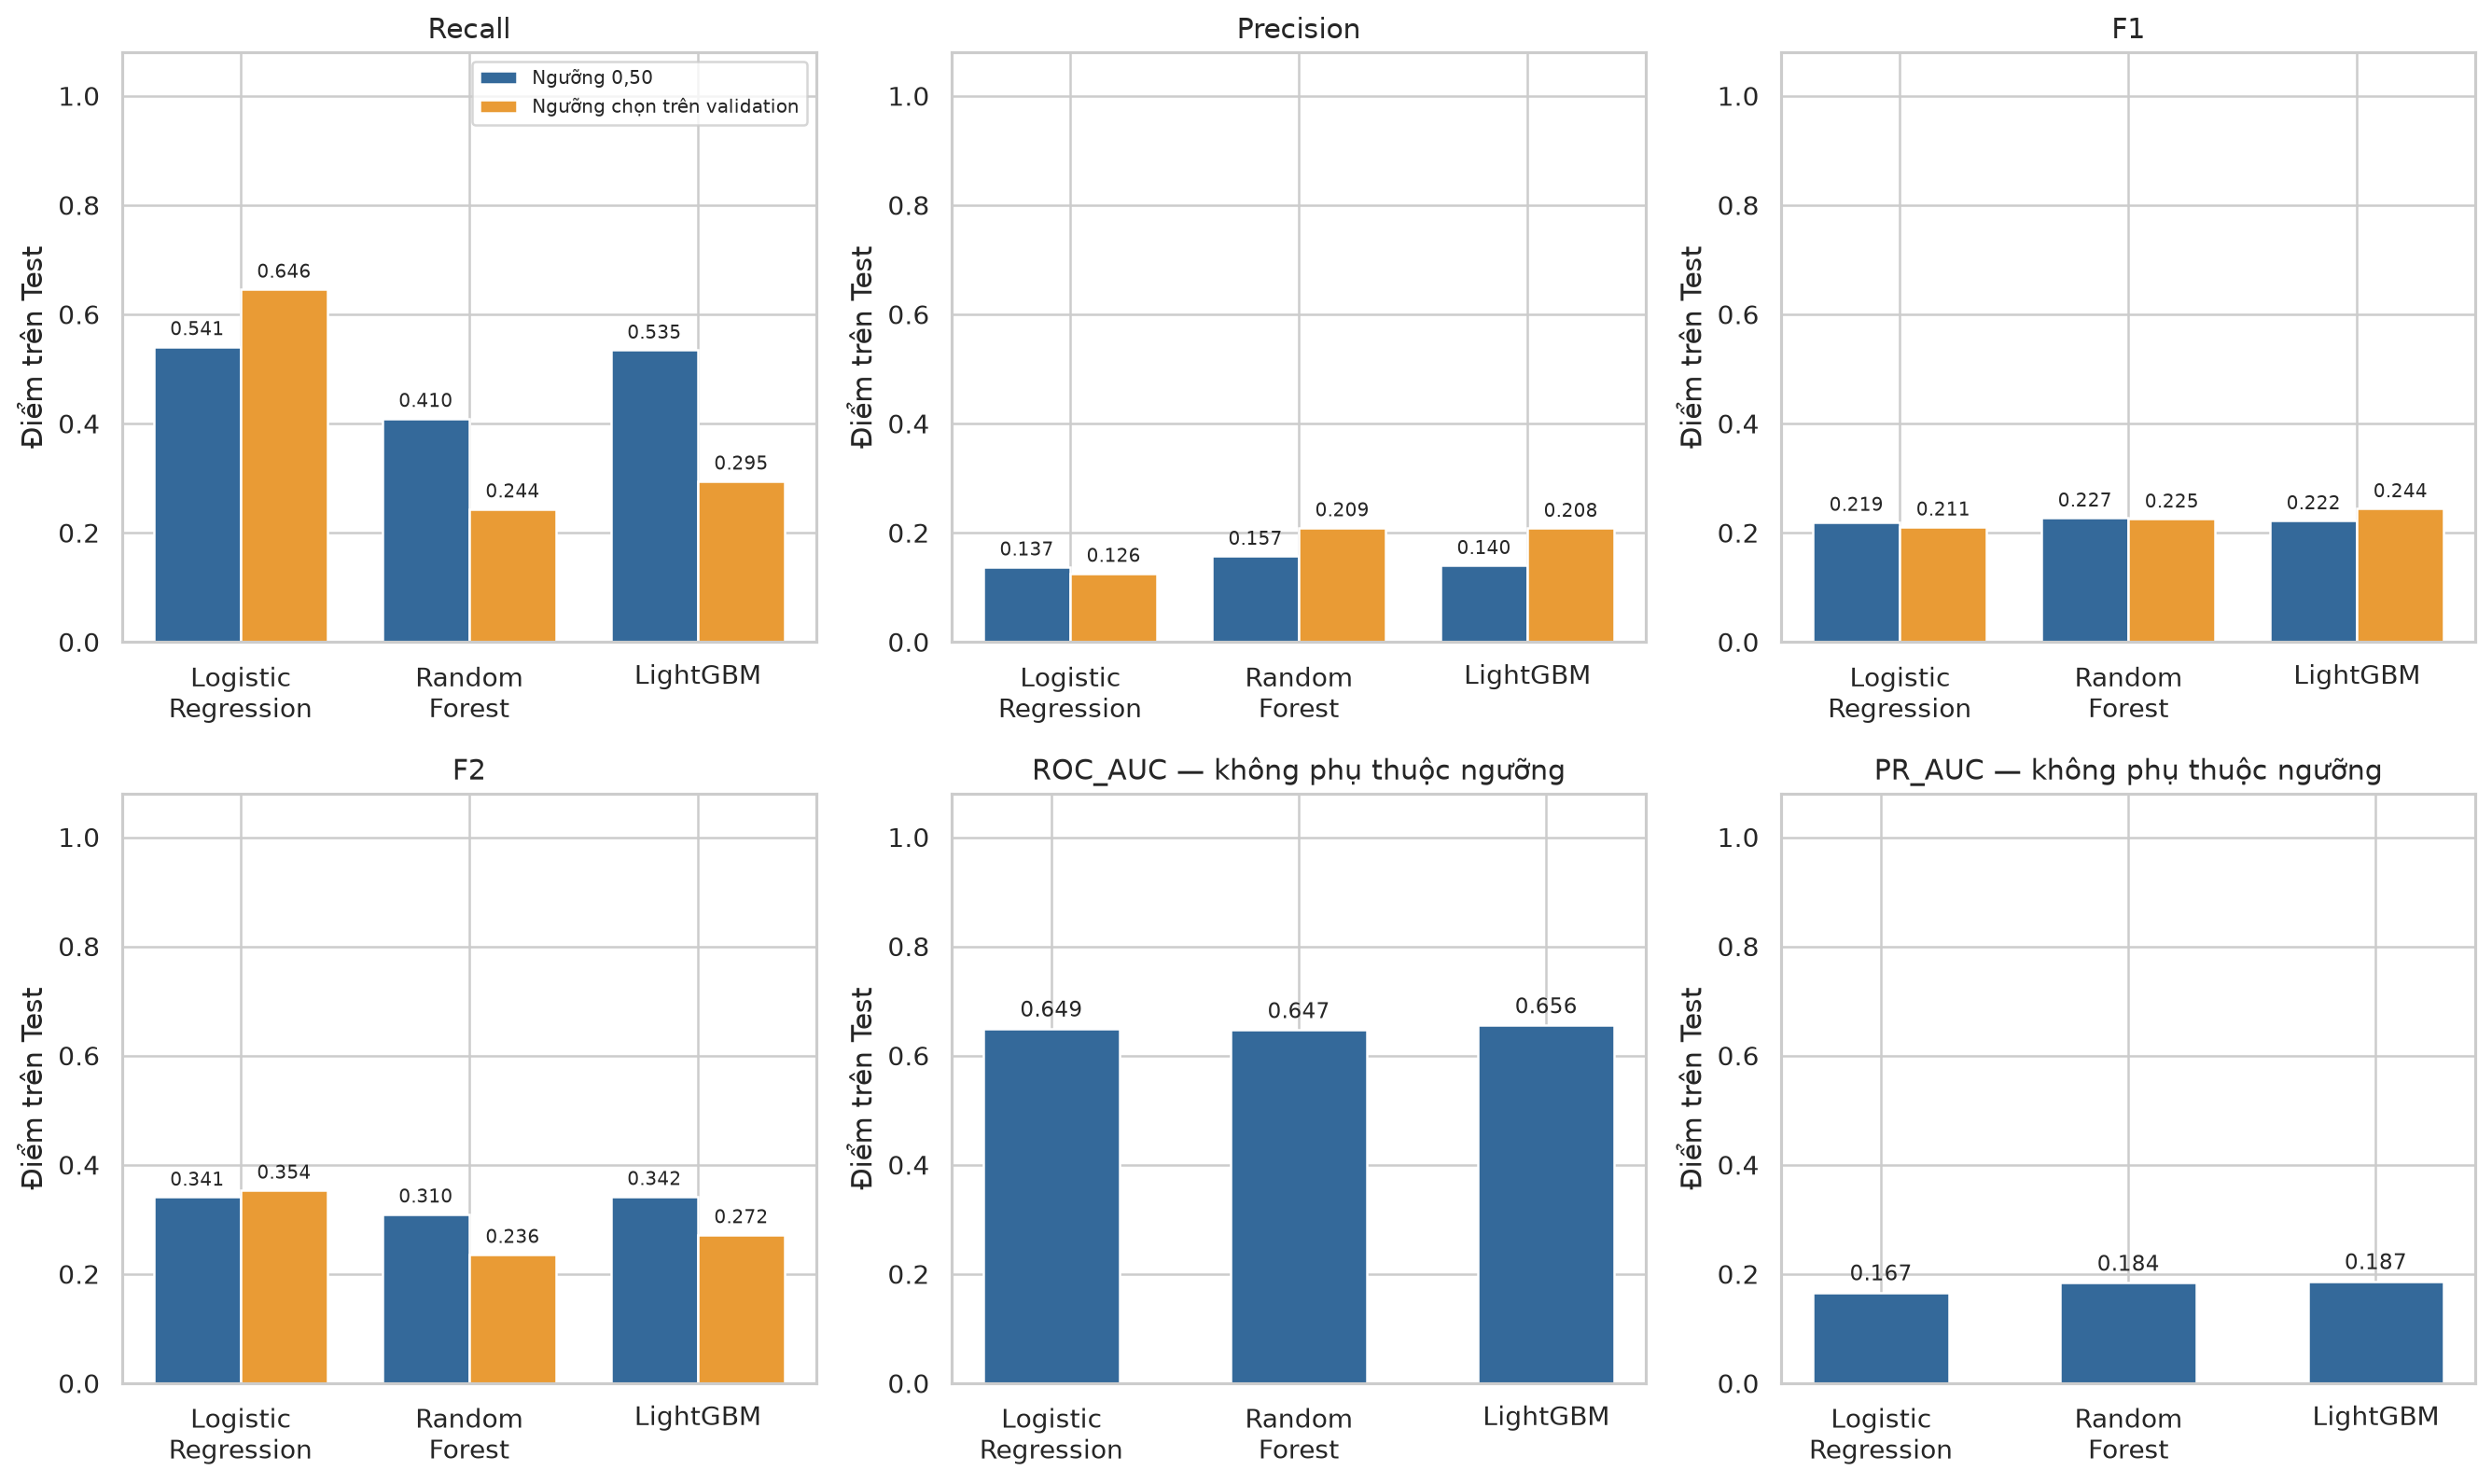

**confusion_matrices**

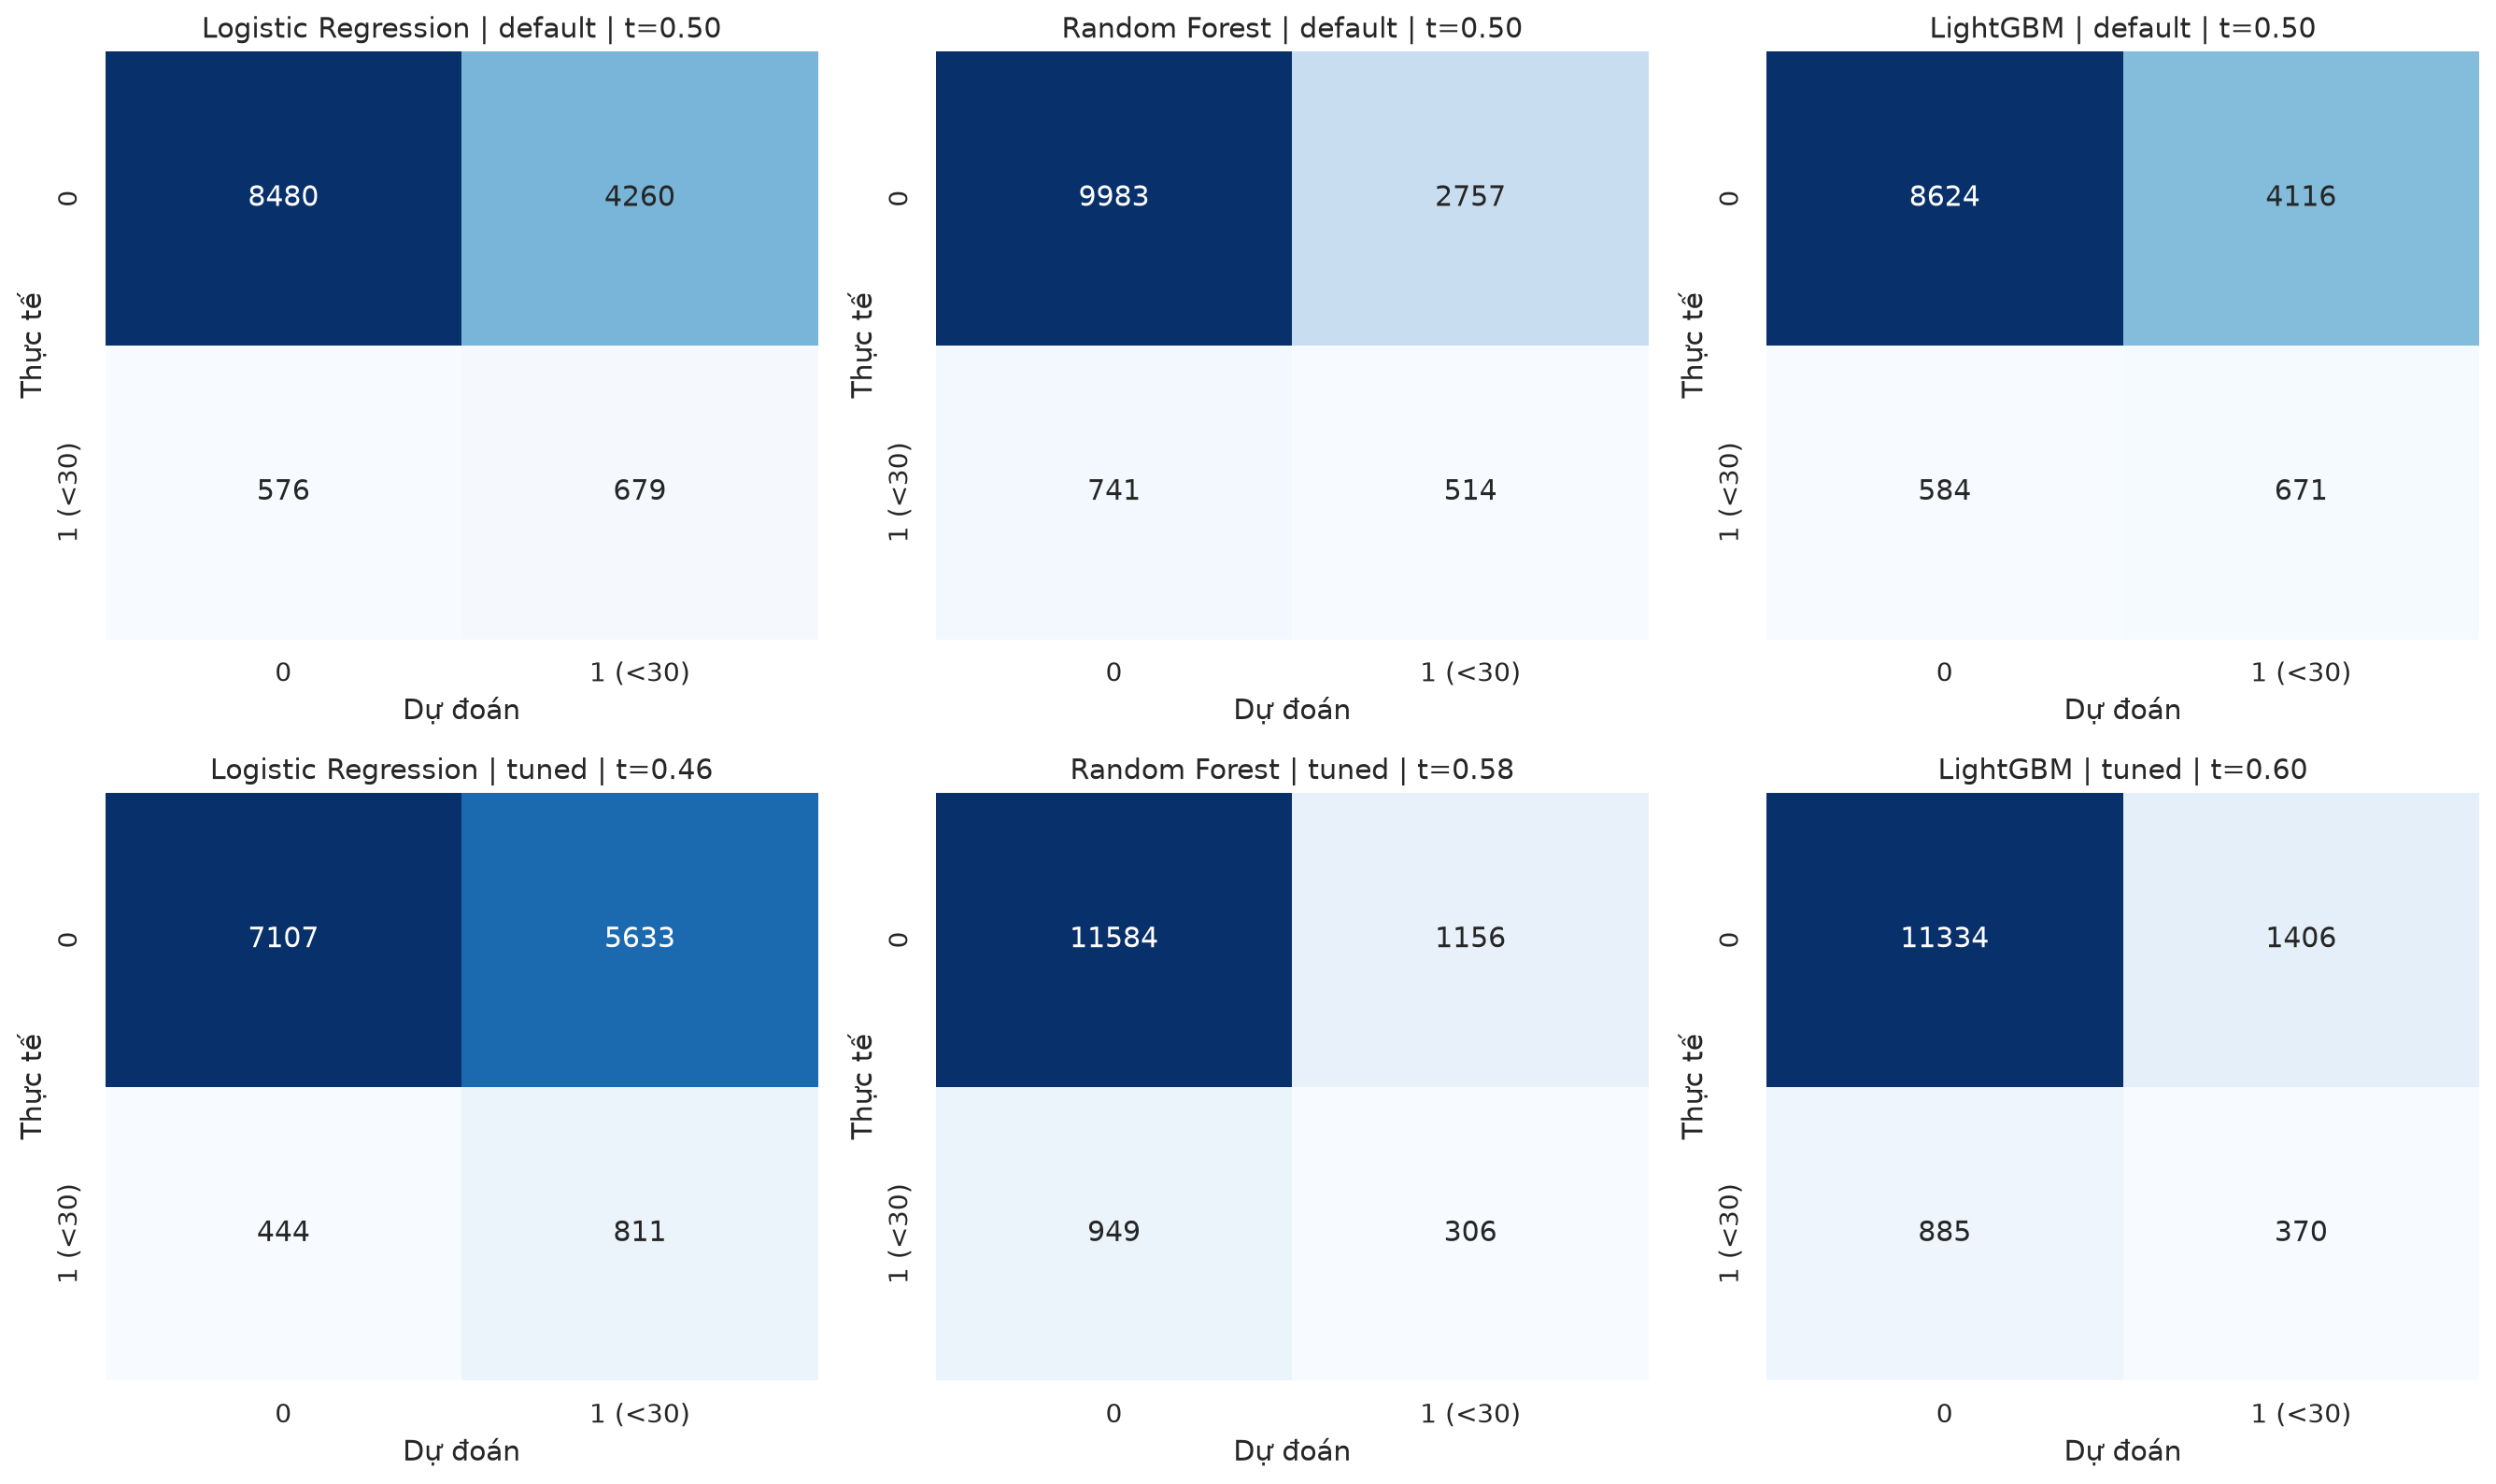

**roc_comparison**

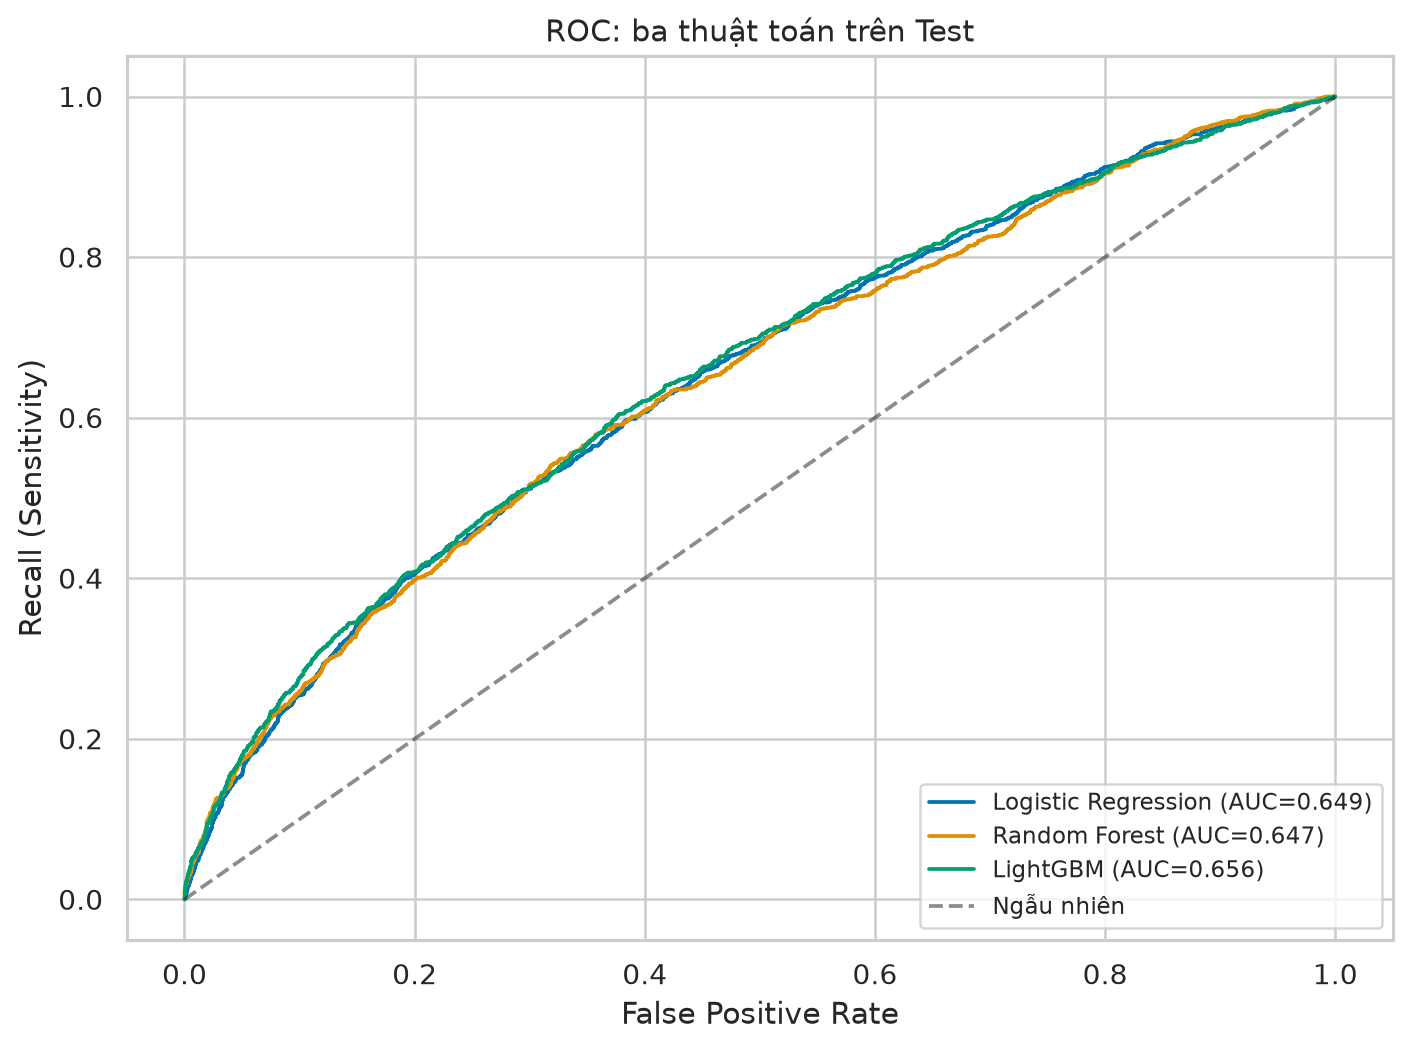

**precision_recall_comparison**

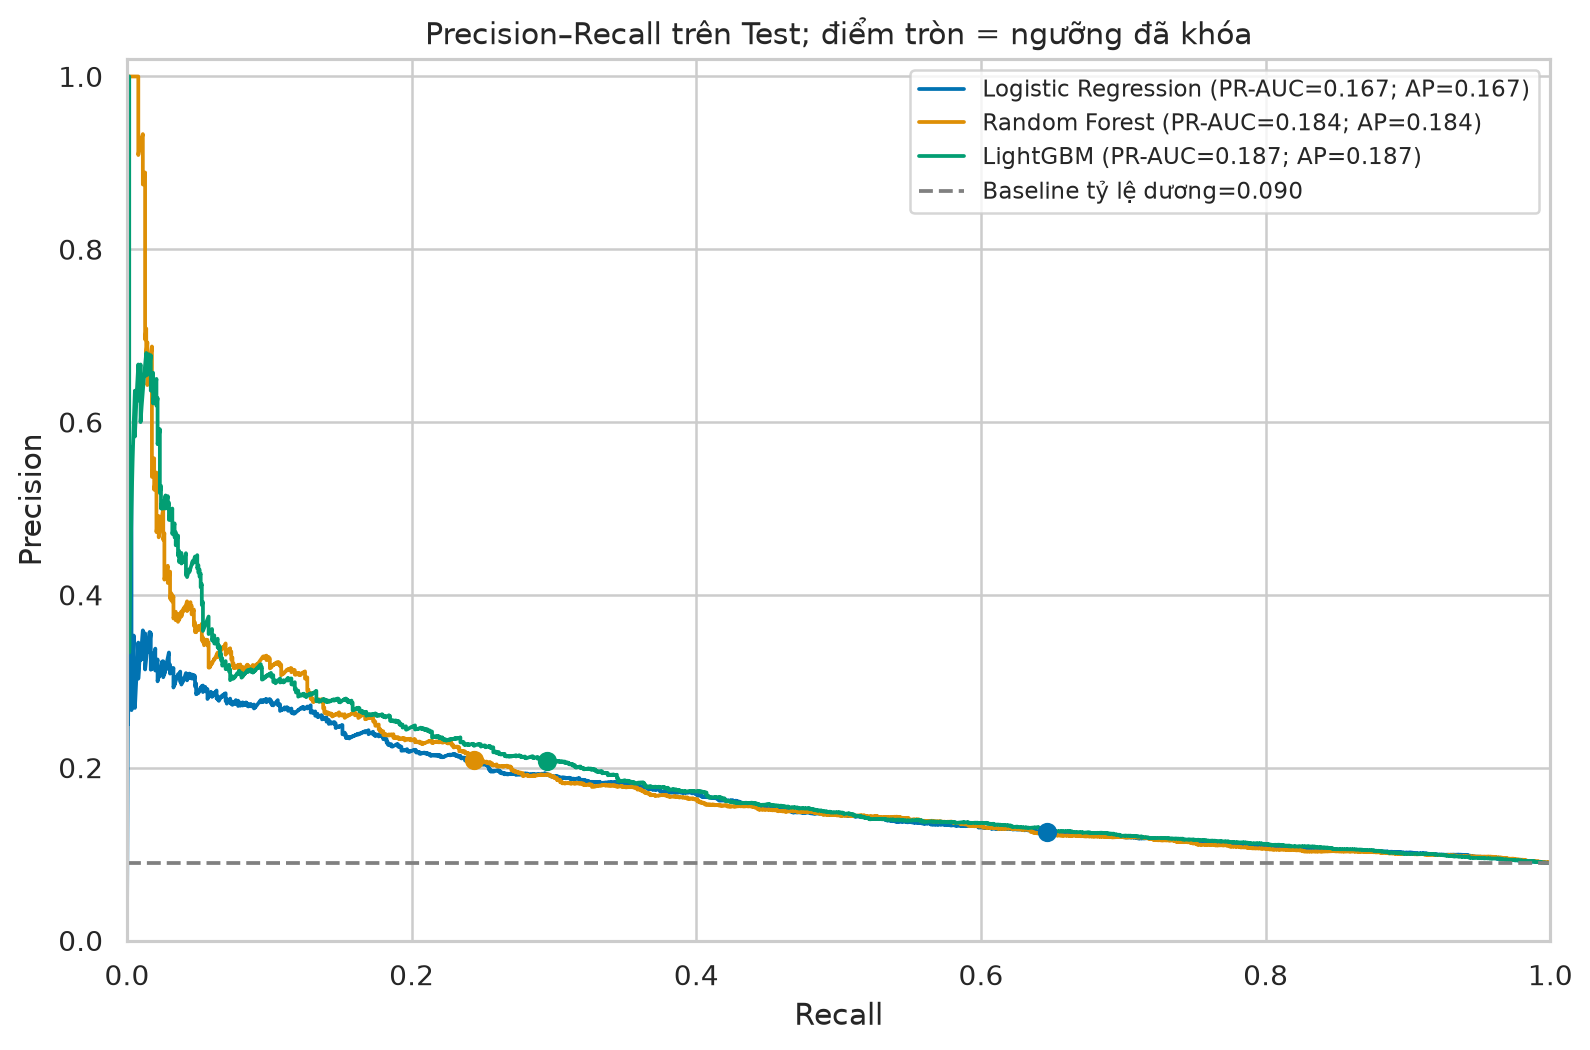

In [13]:
for figure_name in ['model_comparison', 'confusion_matrices', 'roc_comparison', 'precision_recall_comparison']:
    display(Markdown(f'**{figure_name}**'))
    display(Image(filename=experiment['figures'][figure_name], width=1100))


### 6.2. Feature Importance và SHAP

Top 20 của LR dùng |hệ số| trên biến đã biến đổi, RF dùng MDI impurity importance,
LightGBM dùng gain. Không so trực tiếp trị số giữa các thước đo khác nhau.

SHAP trên tối đa 300 hàng Train của LightGBM, raw log-odds, tree-path-dependent.
Đã kiểm tra base value + tổng SHAP khớp raw score. SHAP mô tả mô hình, không chứng minh nhân quả;
các biến tương quan có thể chia sẻ importance. Không dùng Test để tìm thêm biến.

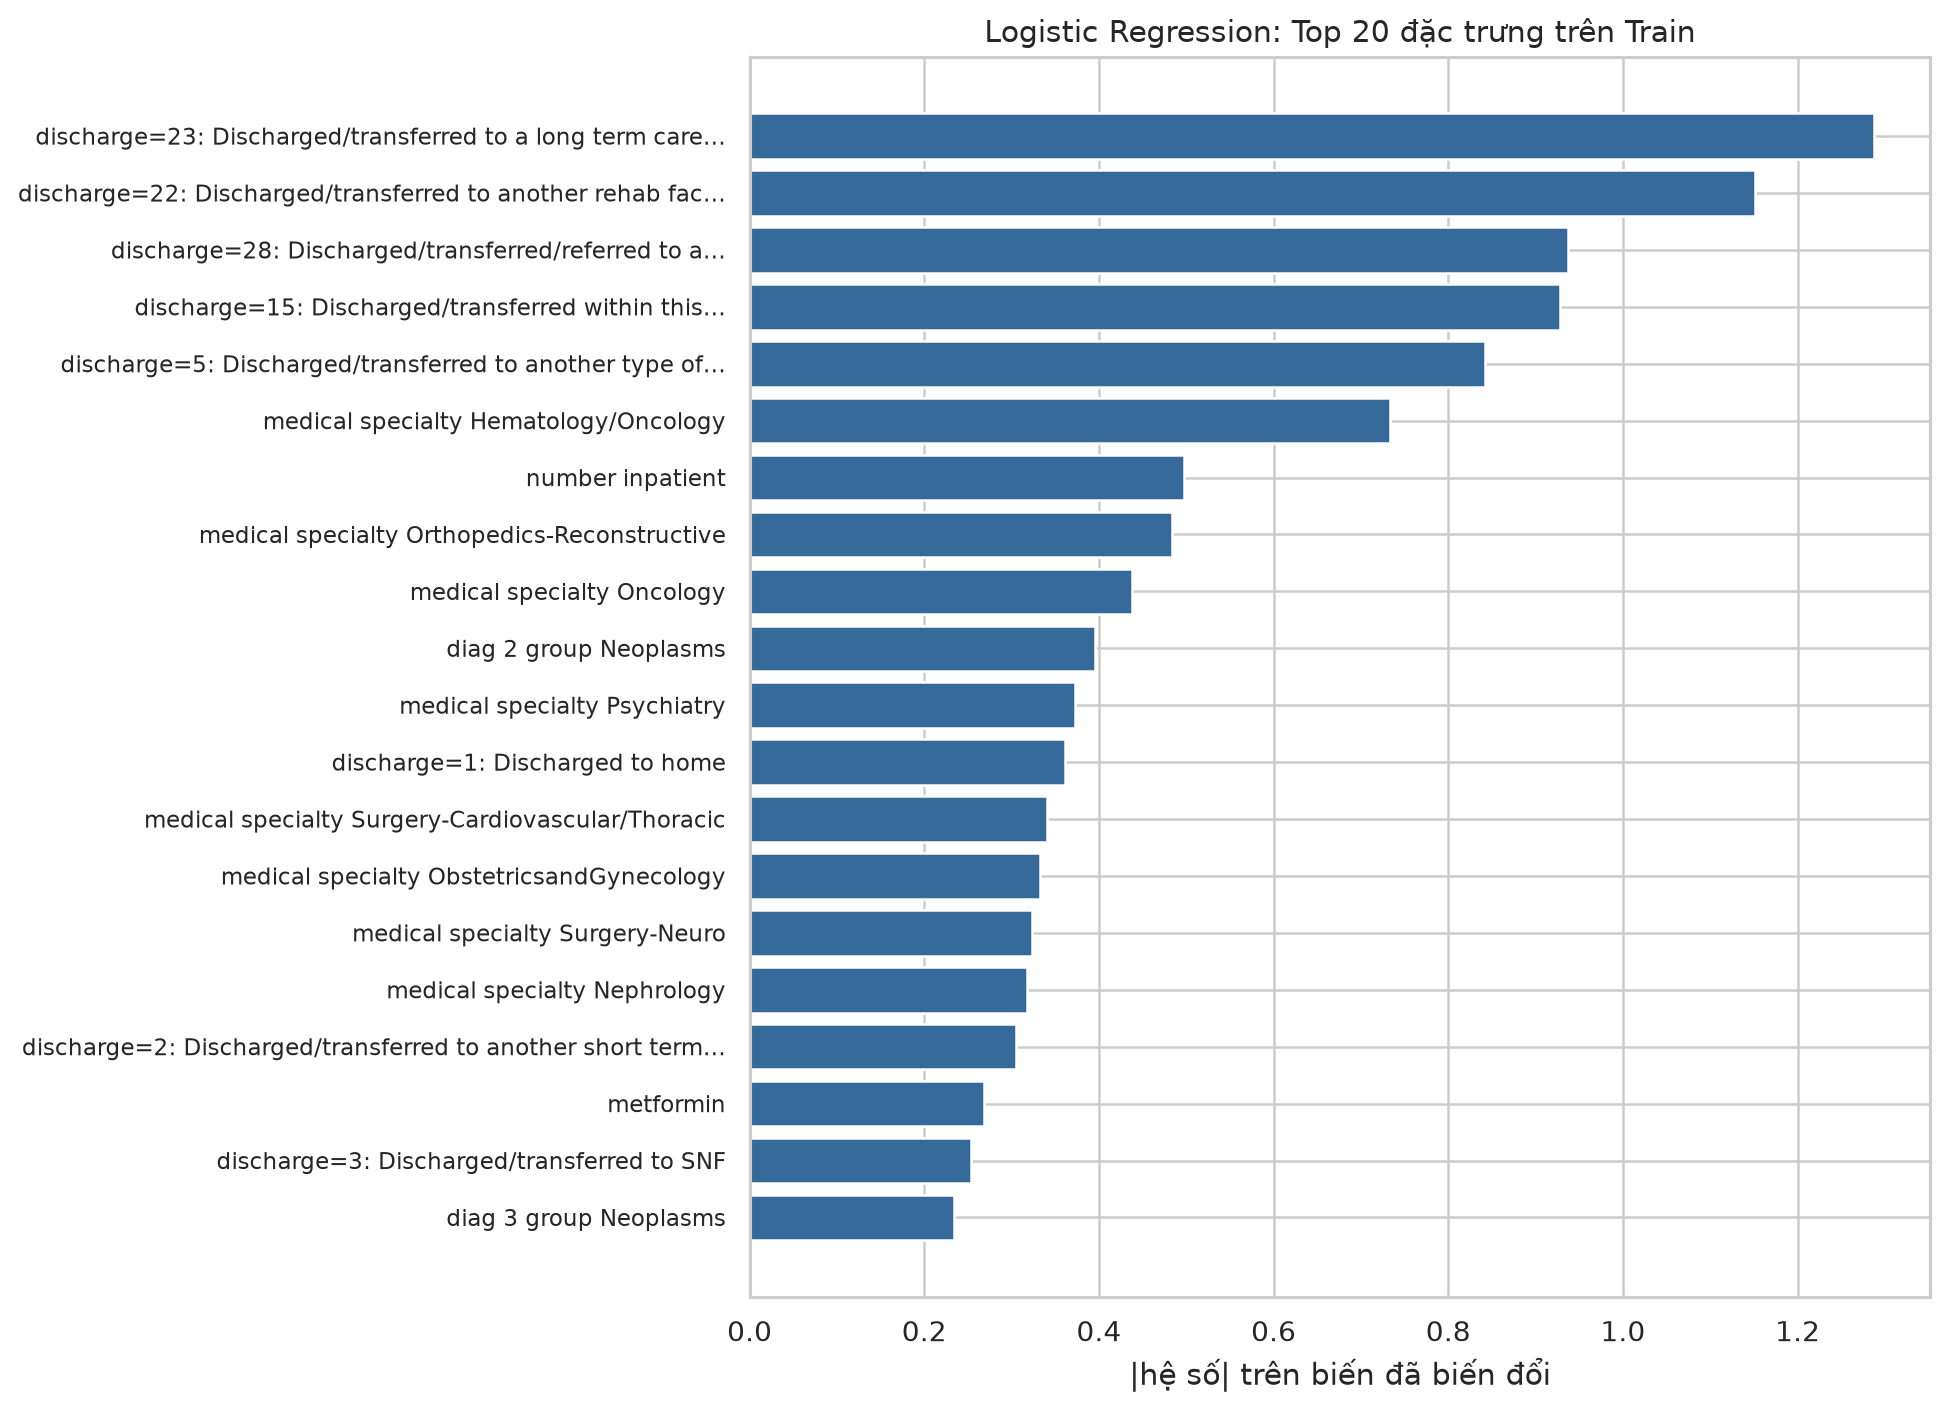

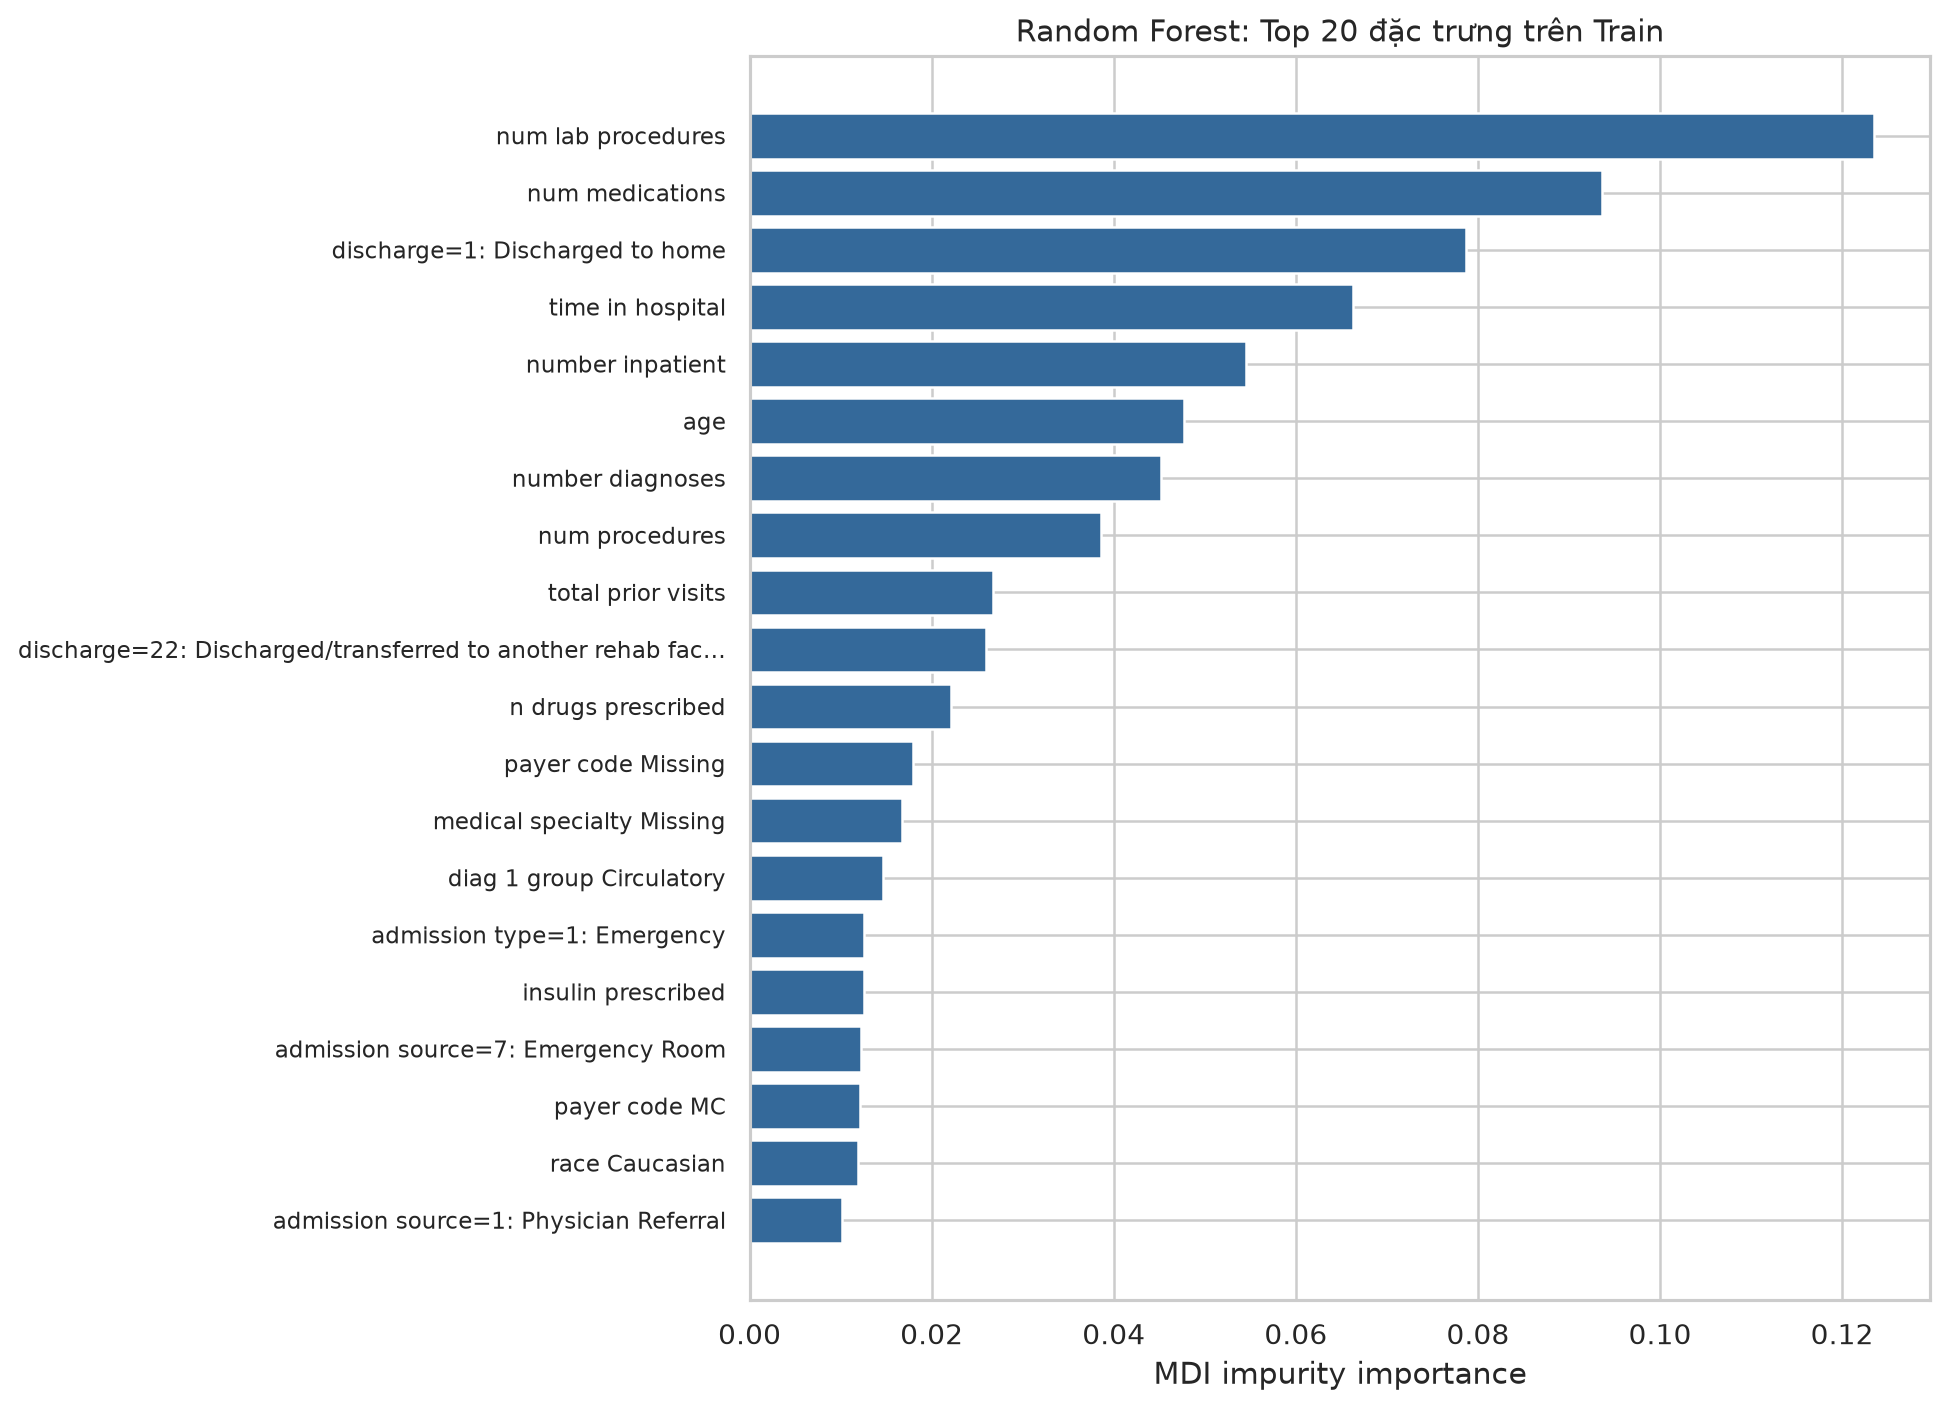

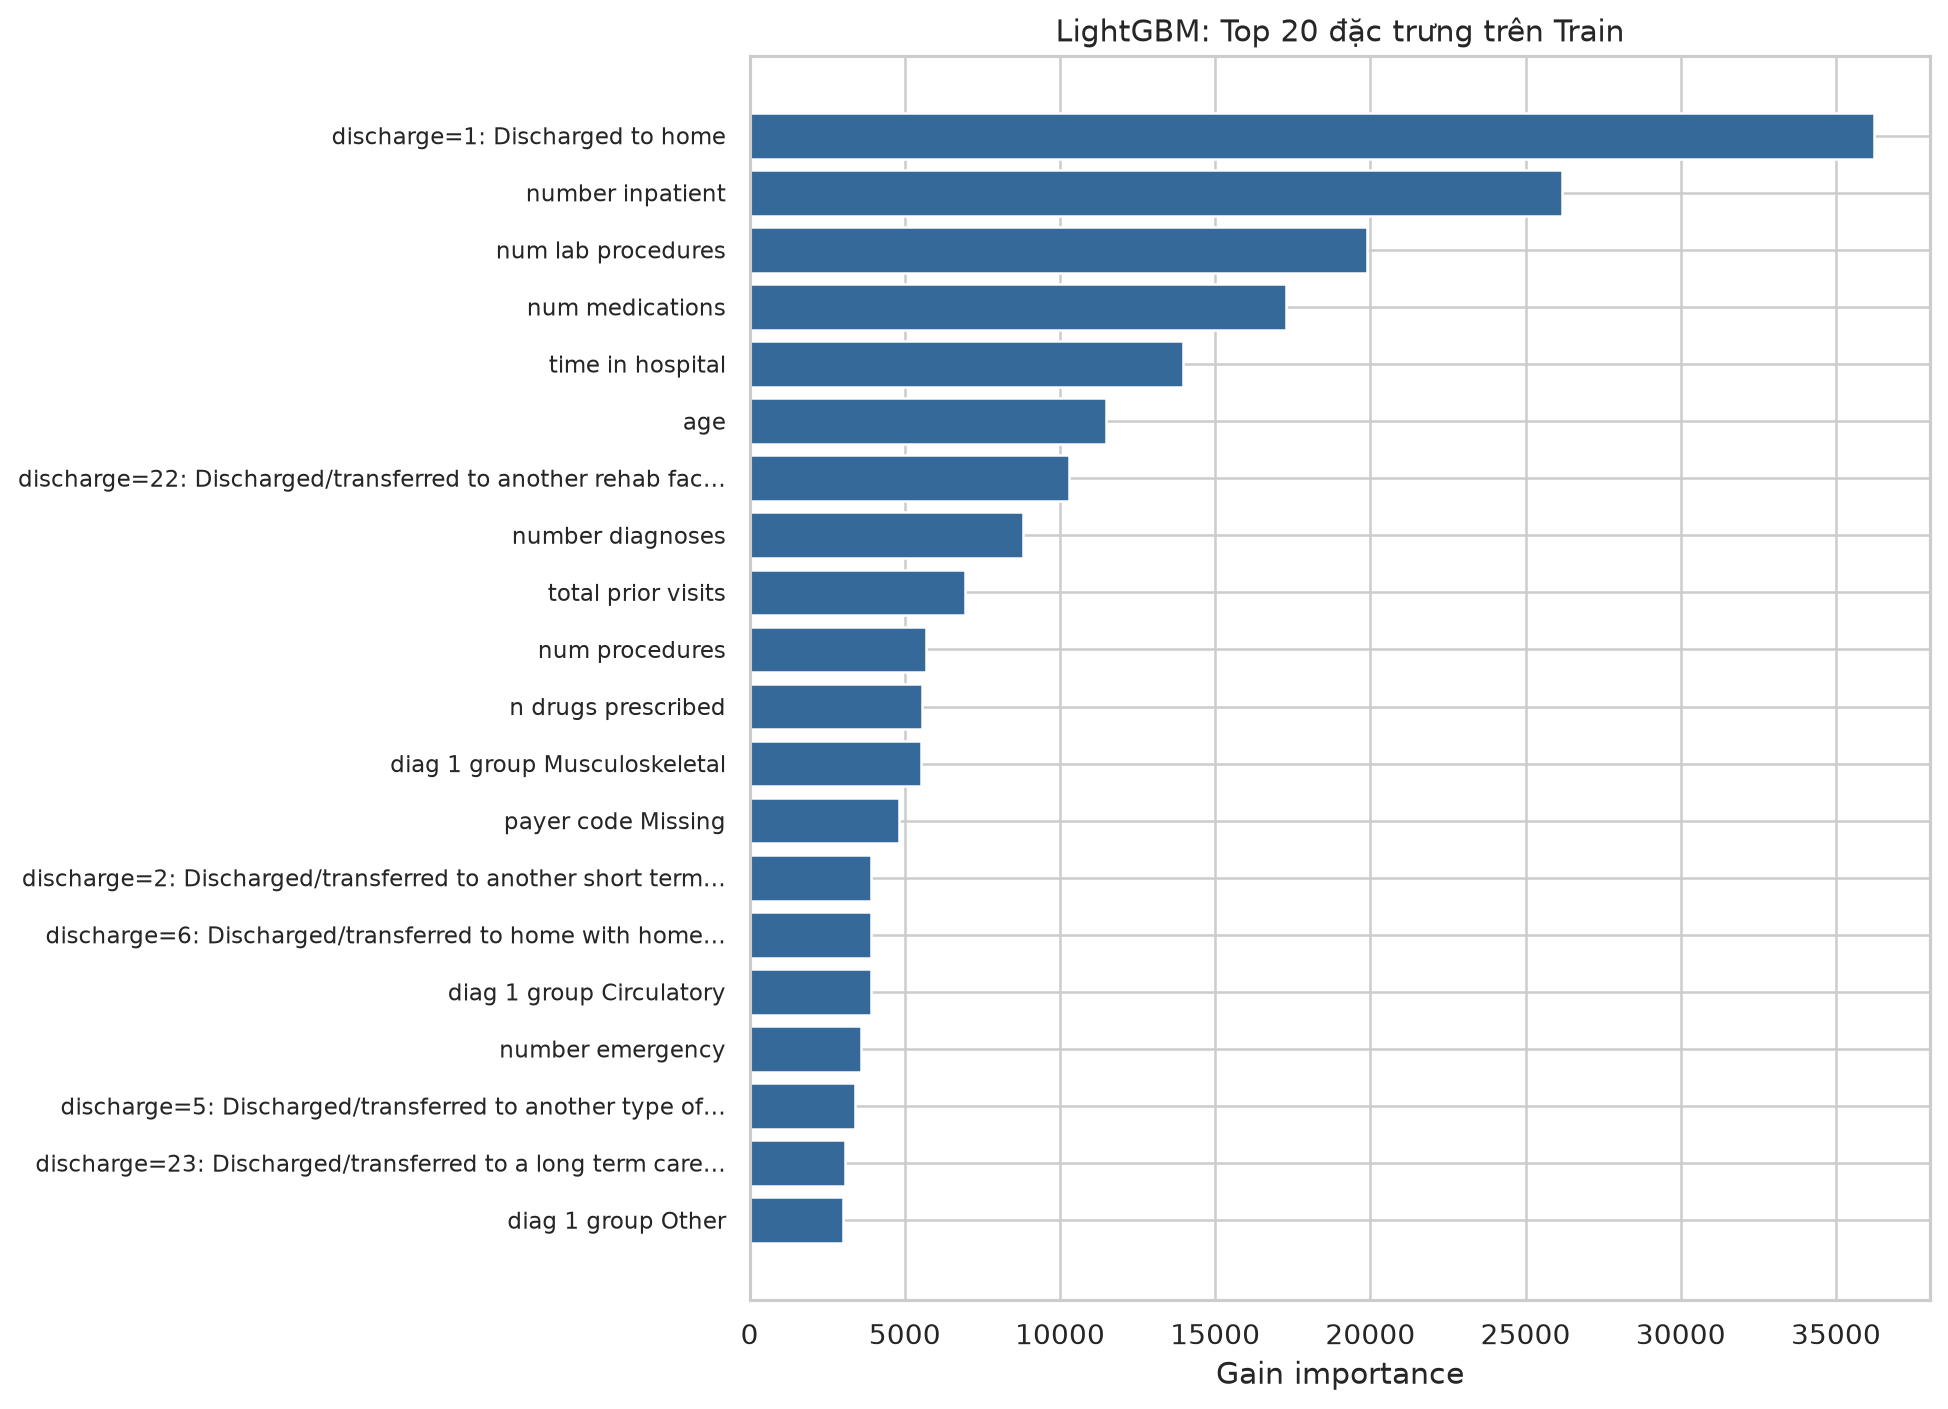

,feature,mean_abs_shap
0,nominal__discharge_disposition_id_Discharged t...,0.226040
1,numeric__number_inpatient,0.106325
2,ordinal__age,0.085317
3,numeric__time_in_hospital,0.072454
4,numeric__num_lab_procedures,0.061033
5,nominal__diag_1_group_Circulatory,0.054431
6,nominal__payer_code_Missing,0.051511
7,numeric__total_prior_visits,0.045724
8,numeric__number_diagnoses,0.045041
9,numeric__n_drugs_prescribed,0.042767


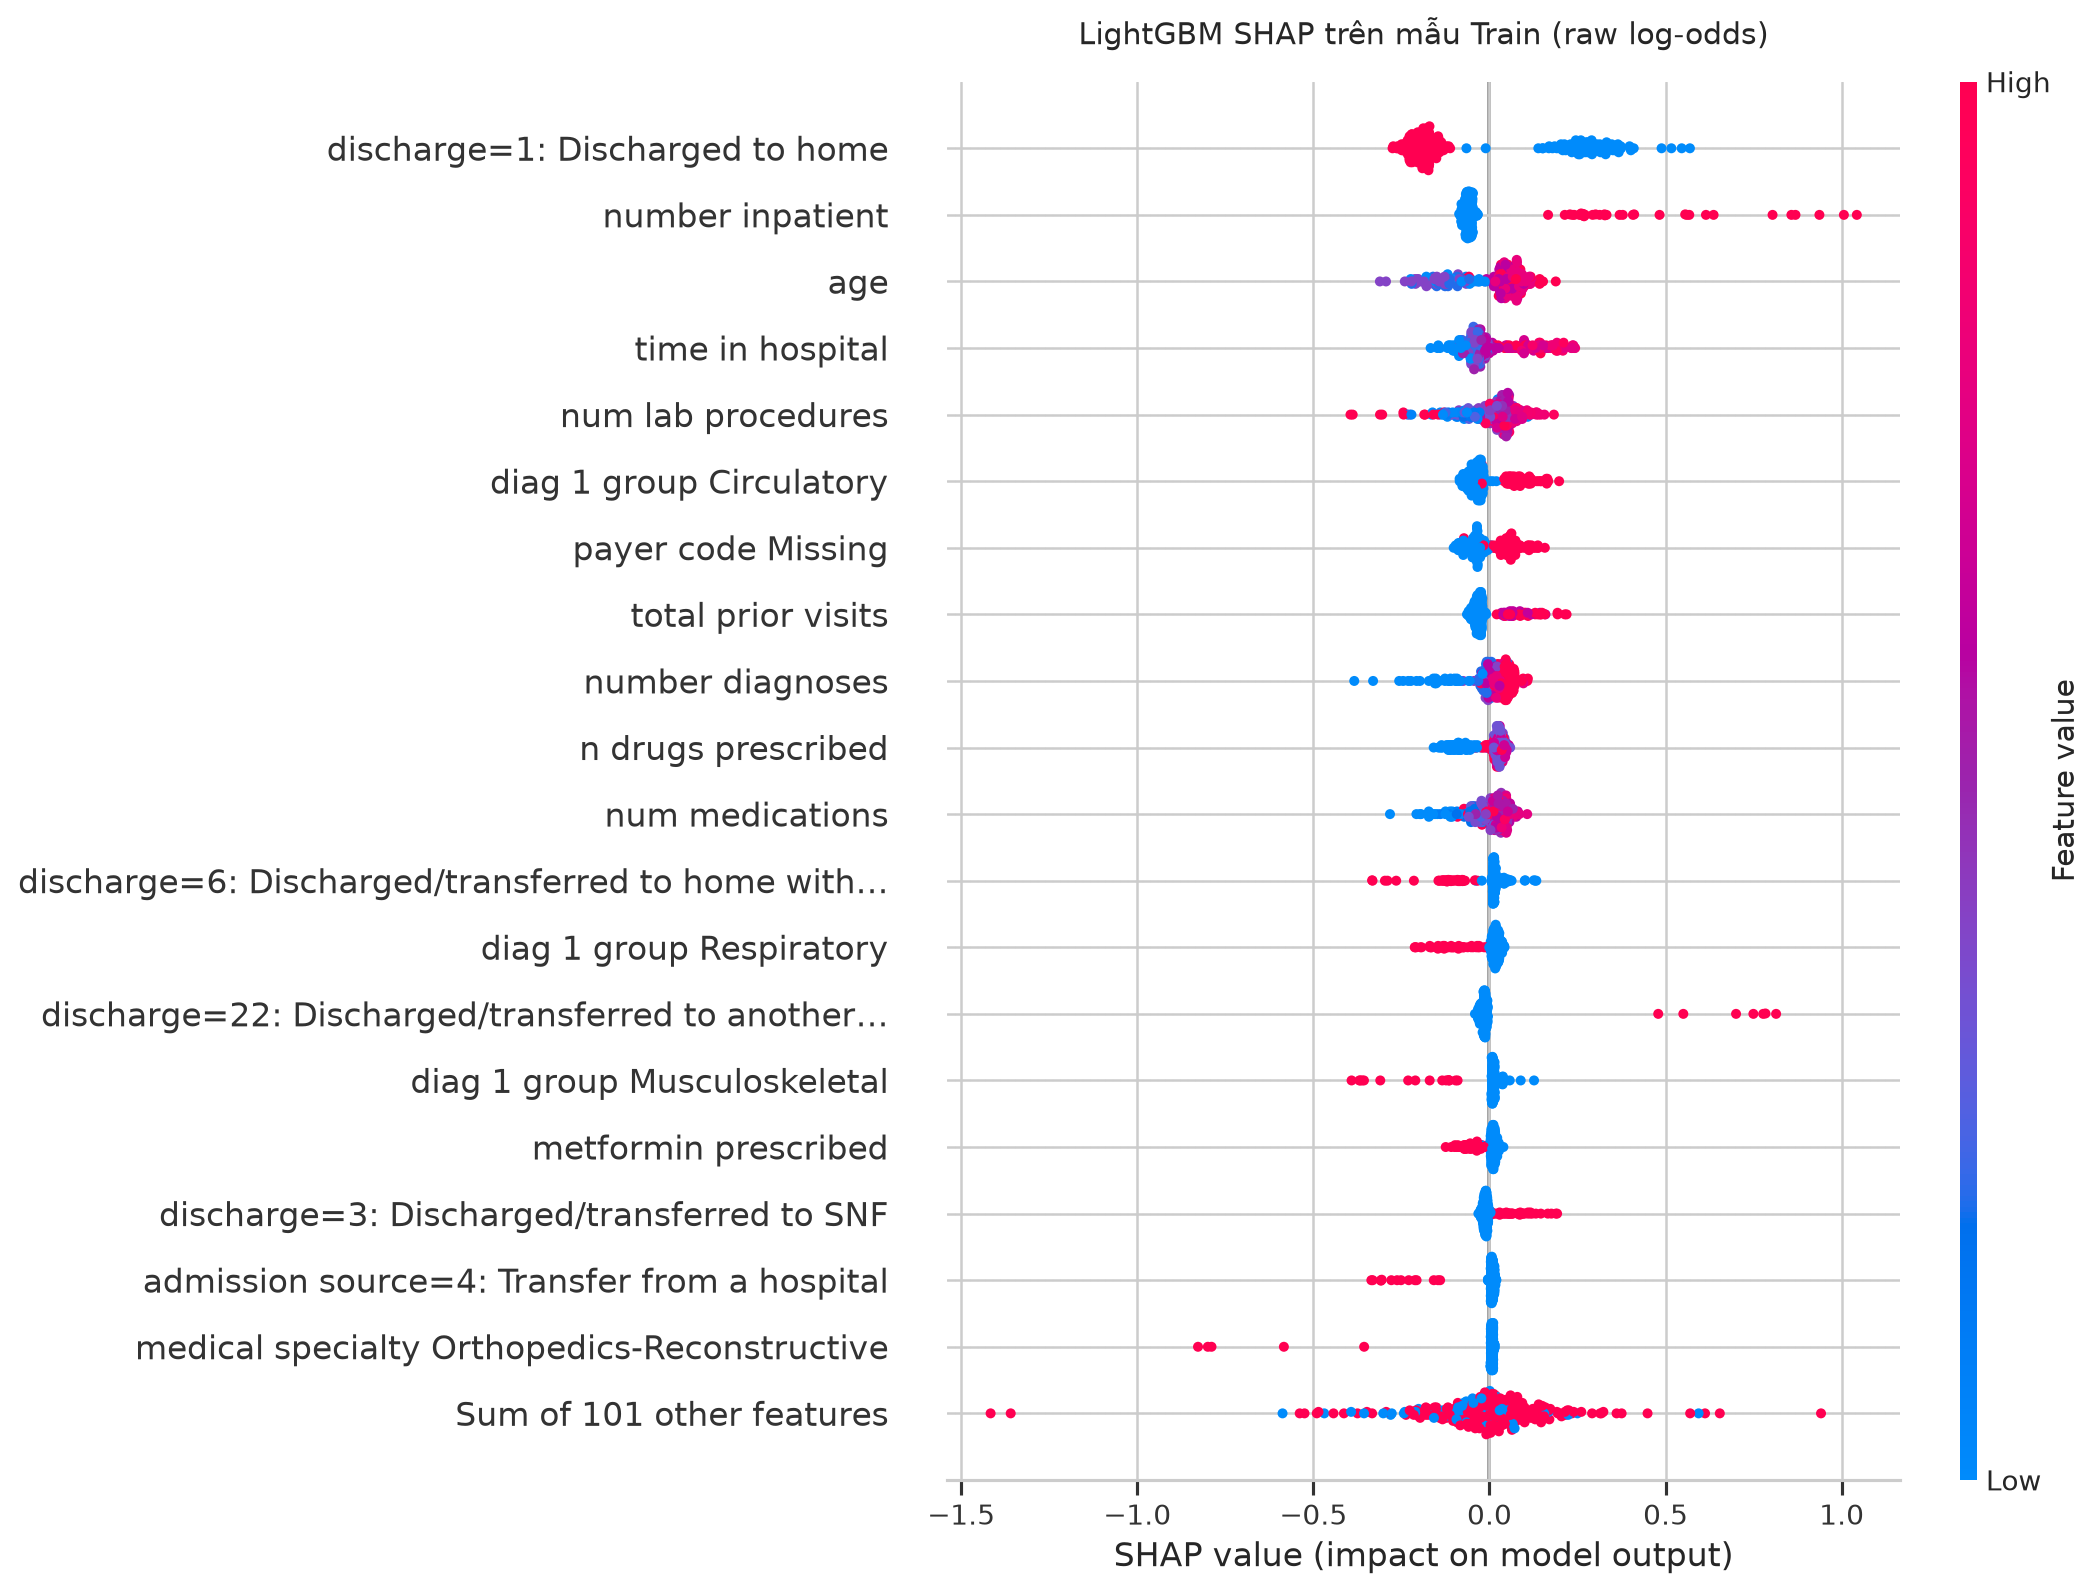

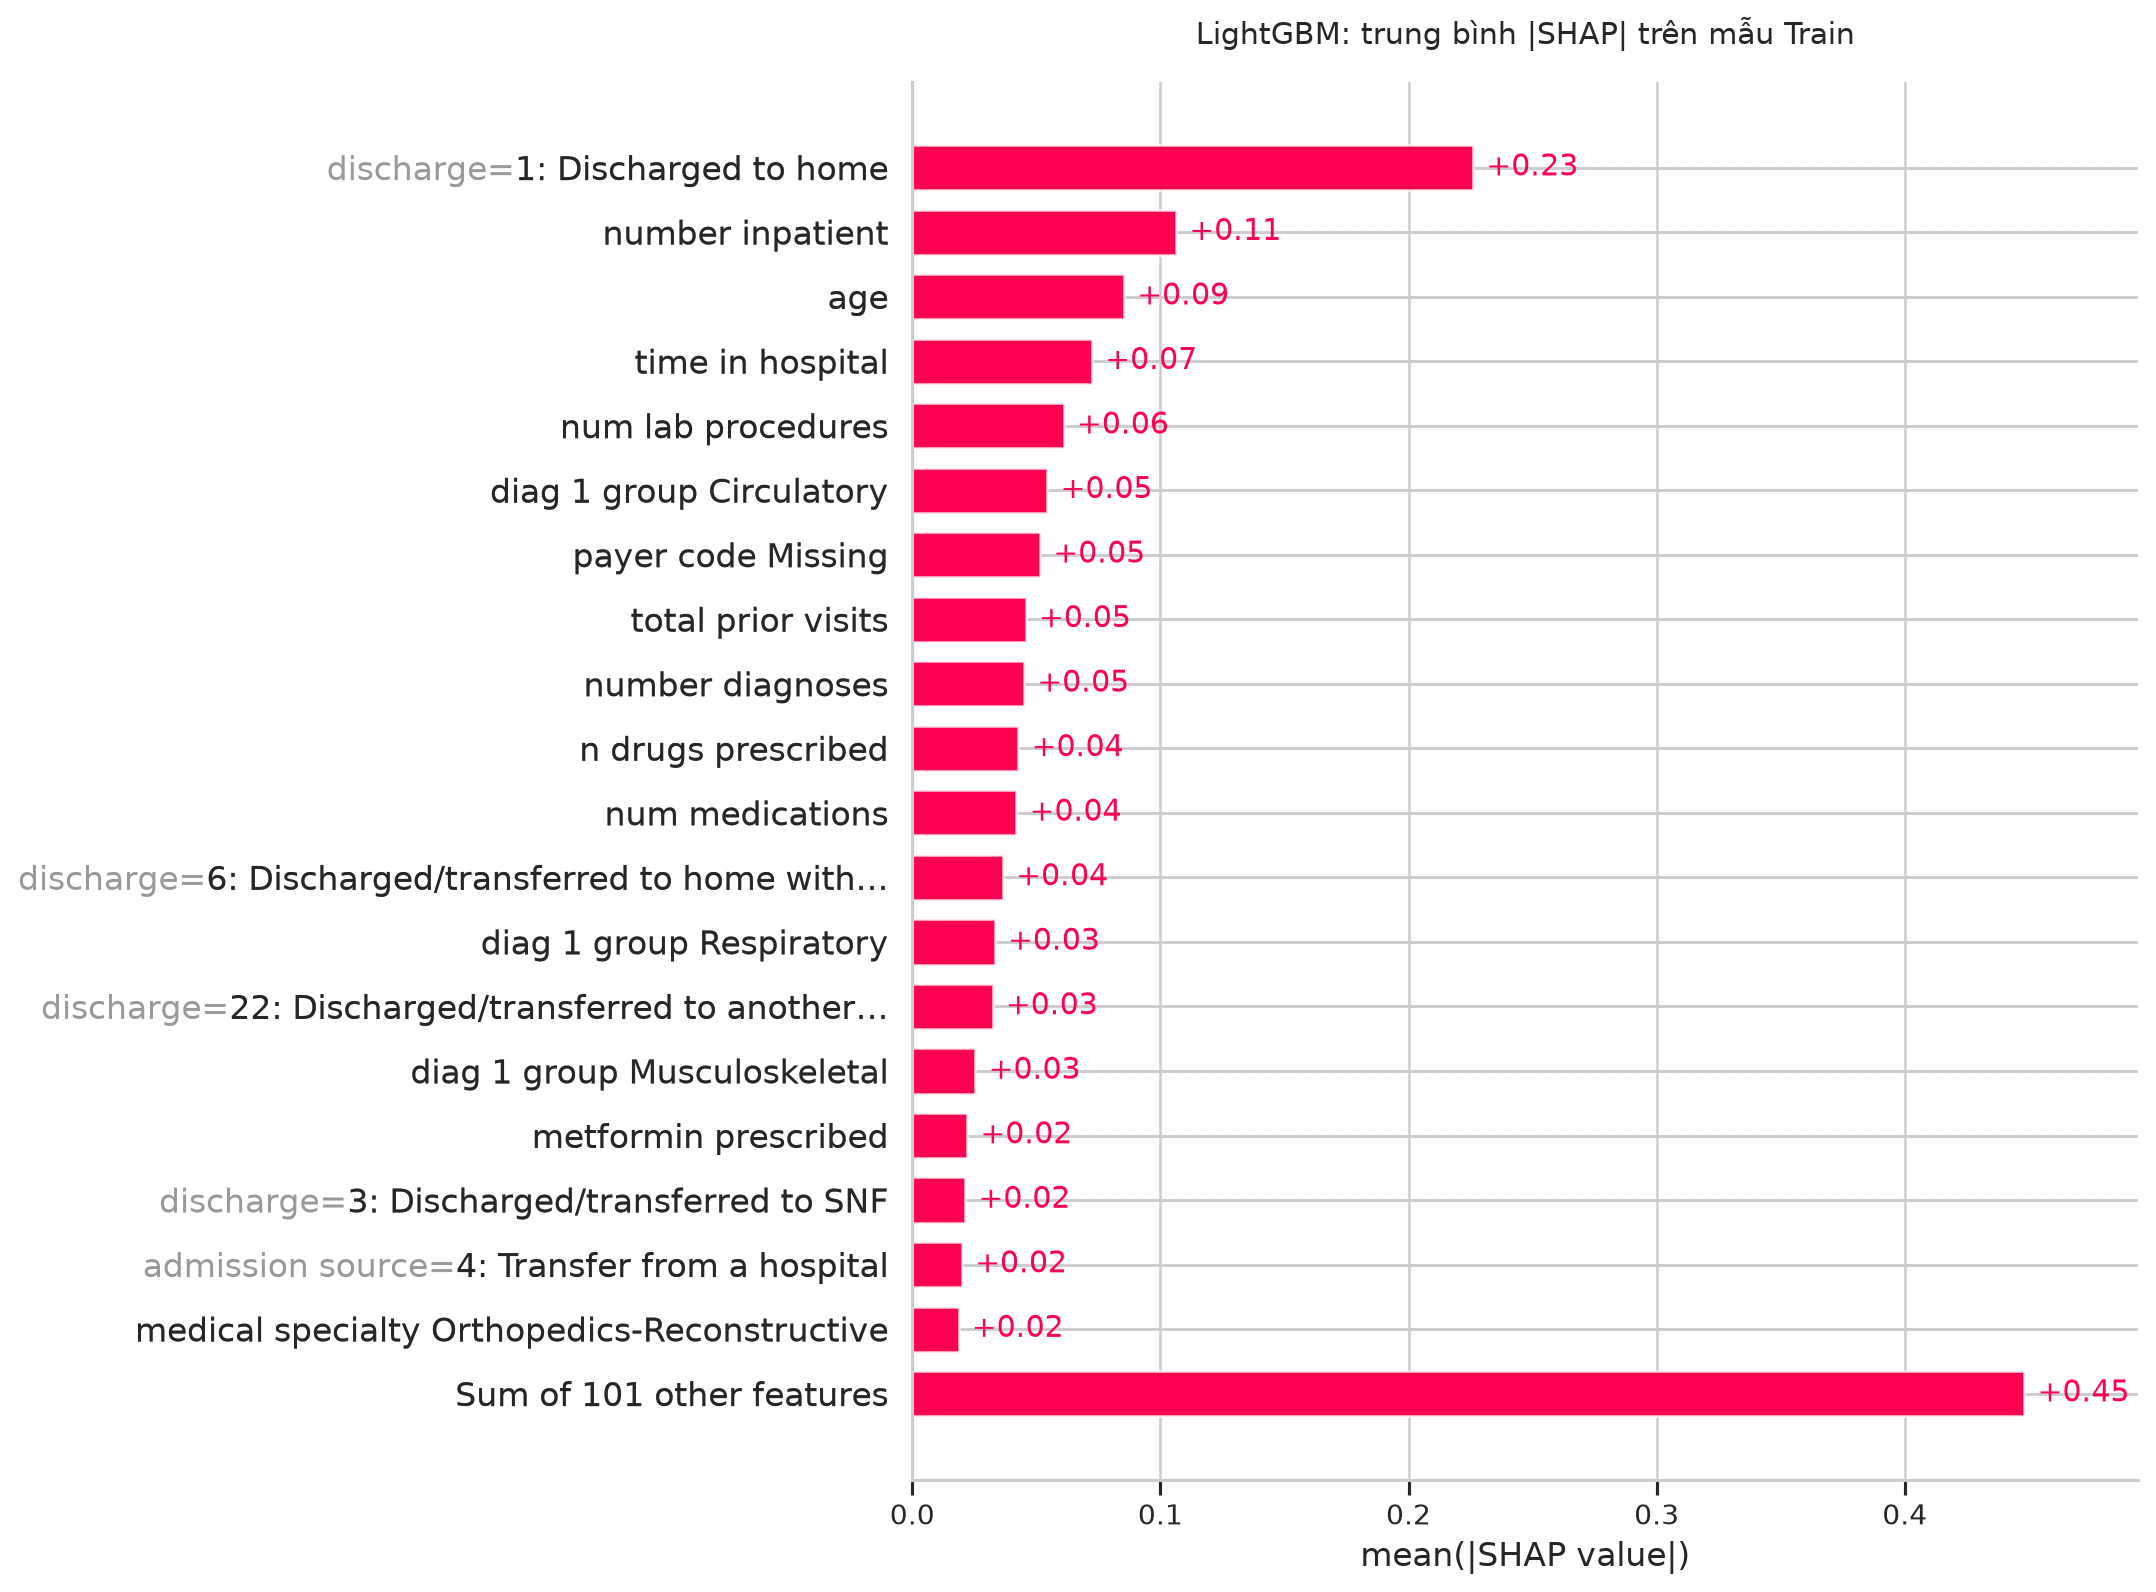

In [14]:
for model_name in ['logistic_regression', 'random_forest', 'lightgbm']:
    display(Image(filename=experiment['figures'][f'feature_importance_{model_name}'], width=1000))
display(pd.read_csv(OUTPUT_DIR / 'tables' / 'shap_lightgbm_importance.csv').head(20))
for figure_name in ['shap_lightgbm_beeswarm', 'shap_lightgbm_bar']:
    display(Image(filename=experiment['figures'][figure_name], width=1050))


### 6.3. Đọc lại và kiểm tra mô hình

Artifact .joblib là toàn pipeline raw → preprocessing → selection → classifier.
Dùng score và threshold trong metadata, vì predict() mặc định dùng 0,50.
Ô dưới kiểm tra pipeline đọc lại khớp dự đoán Test đã lưu, không chọn/tuning lại.

Báo cáo ở outputs/report.md; CSV và PNG ở outputs/tables và outputs/figures.
Kết quả trên dữ liệu lịch sử và bản ghi đại diện theo ID chưa phải kiểm định triển khai lâm sàng.

In [15]:
metadata = json.loads((OUTPUT_DIR / 'artifacts' / 'best_model_metadata.json').read_text(encoding='utf-8'))
assert metadata['model'] == chosen_model
best_pipeline = joblib.load(metadata['artifact_path'])
scores = best_pipeline.predict_proba(splits.X_test.iloc[:25])[:, 1]
predicted = (scores >= metadata['threshold']).astype(int)
saved = pd.read_csv(OUTPUT_DIR / 'tables' / 'test_predictions.csv')
np.testing.assert_allclose(scores, saved[f'{chosen_model}_score'].iloc[:25], rtol=1e-8, atol=1e-8)
np.testing.assert_array_equal(predicted, saved[f'{chosen_model}_tuned'].iloc[:25])
display(pd.DataFrame({'score': scores, 'predicted_readmission_30d': predicted}))
chosen_test = comparison.loc[comparison['model'].eq(chosen_model) & comparison['operating_point'].eq('tuned')].iloc[0]
display(Markdown(f"**Mô hình chọn trên validation: {metadata['label']}**, threshold **{metadata['threshold']:.2f}**. "
    f"Test: Recall **{chosen_test['Recall']:.2%}**, Precision **{chosen_test['Precision']:.2%}**, F2 **{chosen_test['F2']:.3f}**."))
print('Hoàn thành đầy đủ Bước 1–6. Báo cáo:', OUTPUT_DIR / 'report.md')


,score,predicted_readmission_30d
0,0.504623,0
1,0.411526,0
2,0.513225,0
3,0.717065,1
4,0.546174,0
5,0.645923,1
6,0.479645,0
7,0.261229,0
8,0.448974,0
9,0.576642,0


**Mô hình chọn trên validation: LightGBM**, threshold **0.60**. Test: Recall **29.48%**, Precision **20.83%**, F2 **0.272**.

Hoàn thành đầy đủ Bước 1–6. Báo cáo: D:\DataMining\outputs\report.md


### Tài liệu tham khảo
- [UCI: Diabetes 130-US Hospitals for Years 1999–2008](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008).
- [Strack et al. (2014): cohort và nhóm ICD-9, Table 1–2](https://pmc.ncbi.nlm.nih.gov/articles/PMC3996476/).
- [scikit-learn: data leakage và Pipeline](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html).
- [ANOVA F-test](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html).
- [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html), [threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html), [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- [LightGBM weights](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html).
- [SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).
